# Type-5 rule + exception with high-dimensional Gaussian inputs

**Question.** When we hold the *total number of exception exposures* fixed, does back-loading them (curriculum) help peripheral generalisation over spreading them uniformly (standard)? We sweep this comparison across input noise σ, network width K, and training length T.

**Task.** 8 discrete prototype vectors — 6 rule + 2 exception — from the classic Type-5 task, embedded in R^d. First 3 dims carry the ±1 signal (rule = `NOT(x[0])`; two exception prototypes violate it); the remaining d − 3 dims are zero. Per trial: pick a prototype according to the schedule, add fresh isotropic `N(0, σ² I_d)`. Labels are 0/1.

**Model.** One-hidden-layer ReLU net (`K` units, input dim `d`), random init `W_ij ~ N(0, init_std²/d)`, `v_k ~ N(0, init_std²)`, `b = c = 0`. Trained by single-trial online SGD (`batch_size=1`, `lr=0.01`) with BCE-with-logits.

**Two matched schedules** — both have mean `p_exception = 0.25`, so the same expected total exception count over `T` steps. They differ only in temporal ordering.
- **standard**: constant `p_exception = 0.25`.
- **curriculum** (`ramp_frac = 1.0`): linear ramp `0 → 0.5` over full training.

**Evaluation.** Every `eval_every` steps, evaluate on the **clean** (noise-free) prototype matrix and record central_acc (6 rule prototypes → discrete in `{k/6}`), peripheral_acc (2 exception prototypes → discrete in `{0, 0.5, 1.0}`), all_acc, and their BCE losses. Prediction rule: `logit ≥ 0 → 1`.

**Two sweeps** below:
- **Sweep A** — σ facets × training length T, at fixed K.
- **Sweep B** — K facets × training length T, at fixed σ.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
from dataclasses import dataclass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float32)

print("Using device:", device)

Using device: cuda


In [2]:
INPUT_DIM = 3  # 3 signed bits — the only relevant features


@dataclass
class BooleanTaskSplit:
    x_central: np.ndarray
    y_central: np.ndarray
    x_peripheral: np.ndarray
    y_peripheral: np.ndarray


def make_type5_task(rule_feature: int = 0, signed_inputs: bool = True) -> BooleanTaskSplit:
    """Type-5 rule+exception task on the 3-bit hypercube (see source notebook)."""

    x_central = np.array([
        [1, 1, 1],
        [1, 0, 0],
        [1, 0, 1],
        [0, 1, 1],
        [0, 0, 0],
        [0, 0, 1],
    ], dtype=np.float32)
    y_central = np.array([0, 0, 0, 1, 1, 1], dtype=np.float32)

    x_peripheral = np.array([[0, 1, 0], [1, 1, 0]], dtype=np.float32)
    y_peripheral = np.array([0, 1], dtype=np.float32)

    if rule_feature != 0:
        perm = list(range(3))
        perm[0], perm[rule_feature] = perm[rule_feature], perm[0]
        x_central = x_central[:, perm]
        x_peripheral = x_peripheral[:, perm]

    if signed_inputs:
        x_central = 2 * x_central - 1
        x_peripheral = 2 * x_peripheral - 1

    return BooleanTaskSplit(
        x_central=x_central.astype(np.float32),
        y_central=y_central.astype(np.float32),
        x_peripheral=x_peripheral.astype(np.float32),
        y_peripheral=y_peripheral.astype(np.float32),
    )


@dataclass
class GaussianType5Task:
    x_central: np.ndarray       # (6, 3)  prototype means
    y_central: np.ndarray       # (6,)
    x_peripheral: np.ndarray    # (2, 3)
    y_peripheral: np.ndarray    # (2,)
    input_noise_std: float
    input_dim: int = INPUT_DIM


def make_gaussian_type5_task(noise_std: float = 0.3, rule_feature: int = 0) -> GaussianType5Task:
    """Type-5 prototypes in R^3 (the 3 signed bits).

    Per-trial isotropic Gaussian noise is added in `make_trial_sequence_gaussian`.
    Evaluation happens on the clean prototype matrices carried on the task object."""
    base = make_type5_task(rule_feature=rule_feature, signed_inputs=True)
    return GaussianType5Task(
        x_central=base.x_central.astype(np.float32),
        y_central=base.y_central,
        x_peripheral=base.x_peripheral.astype(np.float32),
        y_peripheral=base.y_peripheral,
        input_noise_std=noise_std,
    )

In [3]:
class GaussianReLUNet(nn.Module):
    """Stripped-down 1-hidden-layer ReLU net for the Gaussian-input variant.

    Random init only:
        W ~ N(0, init_std**2 / input_dim)   (per-entry)
        b = 0
        v ~ N(0, init_std**2)
        c = 0

    Low-rank init (`rank` < min(K, d)):
        W = A @ B.T with A in R^(K×r), B in R^(d×r) random orthonormal columns
        (QR of Gaussians), scaled so ||W||_F = init_std * √K.  All r singular
        values equal (= init_std * √(K/r)), so PR(W) = r exactly.
    """

    def __init__(self, n_hidden: int = 4, input_dim: int = 100, init_std: float = 0.05,
                 rank: int = None):
        super().__init__()
        self.n_hidden = n_hidden
        self.input_dim = input_dim
        self.rank = rank

        self.W = nn.Parameter(torch.zeros(n_hidden, input_dim))
        self.b = nn.Parameter(torch.zeros(n_hidden))
        self.v = nn.Parameter(torch.zeros(n_hidden))
        self.c = nn.Parameter(torch.zeros(()))

        self.reset_parameters(init_std=init_std)

    def reset_parameters(self, init_std: float):
        with torch.no_grad():
            max_rank = min(self.n_hidden, self.input_dim)
            if self.rank is None or self.rank >= max_rank:
                self.W.normal_(0.0, init_std / math.sqrt(self.input_dim))
            else:
                self._init_low_rank_W(self.rank, init_std)
            self.b.zero_()
            self.v.normal_(0.0, init_std)
            self.c.zero_()

    def _init_low_rank_W(self, r: int, init_std: float):
        K, d = self.n_hidden, self.input_dim
        A, _ = torch.linalg.qr(torch.randn(K, r))   # (K, r), A^T A = I_r
        B, _ = torch.linalg.qr(torch.randn(d, r))   # (d, r), B^T B = I_r
        W = A @ B.T                                  # (K, d), rank r, ||W||_F^2 = r
        target_frob = init_std * math.sqrt(K)
        W = W * (target_frob / (W.norm() + 1e-12))
        self.W.copy_(W)

    def hidden(self, x):
        return torch.relu(x @ self.W.T + self.b)

    def forward(self, x):
        return self.hidden(x) @ self.v

In [4]:
def curriculum_prob_schedule(
    n_steps: int,
    kind: str = "curriculum",
    p_final: float = 0.5,
    p_start: float = 0.0,
    warmup_frac: float = 0.0,
    ramp_frac: float = 1.0,
    exponential_base: float = 2.0,
):
    """Returns p_exception[t]. See source notebook for the full docstring."""
    if kind == "linear":
        return np.linspace(0.0, p_final, n_steps).astype(np.float32)
    
    if kind == "constant":
        return np.full(n_steps, p_final, dtype=np.float32)

    if kind == "anti_curriculum":
        p = np.zeros(n_steps, dtype=np.float32)
        warmup_steps = int(round(warmup_frac * n_steps))
        ramp_steps = int(round(ramp_frac * n_steps))
        ramp_start = warmup_steps
        ramp_end = min(n_steps, warmup_steps + ramp_steps)
        if ramp_end > ramp_start:
            p[ramp_start:ramp_end] = np.linspace(p_final, p_start, ramp_end - ramp_start)
        if ramp_end < n_steps:
            p[ramp_end:] = p_start
        return p

    if kind != "curriculum":
        raise ValueError(f"Unknown schedule kind: {kind}")

    p = np.zeros(n_steps, dtype=np.float32)
    warmup_steps = int(round(warmup_frac * n_steps))
    ramp_steps = int(round(ramp_frac * n_steps))
    ramp_start = warmup_steps
    ramp_end = min(n_steps, warmup_steps + ramp_steps)
    if ramp_end > ramp_start:
        p[ramp_start:ramp_end] = np.linspace(p_start, p_final, ramp_end - ramp_start)
    if ramp_end < n_steps:
        p[ramp_end:] = p_final
    return p


def make_trial_sequence_gaussian(
    task: GaussianType5Task,
    p_exception,
    seed: int = 0,
    device=None,
):
    """Sample a single-trial SGD sequence: prototype + isotropic Gaussian noise on all d dims.

    Returns X (T, d), y (T,), is_exception (T,), item_index (T,).
    """
    rng = np.random.default_rng(seed)
    n_steps = len(p_exception)
    d = task.input_dim
    sigma = task.input_noise_std

    is_exception = rng.random(n_steps) < p_exception

    X = np.zeros((n_steps, d), dtype=np.float32)
    y = np.zeros(n_steps, dtype=np.float32)
    item_index = np.zeros(n_steps, dtype=np.int64)

    for t in range(n_steps):
        if is_exception[t]:
            j = rng.integers(0, len(task.y_peripheral))
            X[t] = task.x_peripheral[j]
            y[t] = task.y_peripheral[j]
            item_index[t] = j
        else:
            j = rng.integers(0, len(task.y_central))
            X[t] = task.x_central[j]
            y[t] = task.y_central[j]
            item_index[t] = j

    X = X + rng.standard_normal((n_steps, d)).astype(np.float32) * sigma

    X = torch.as_tensor(X, dtype=torch.float32, device=device)
    y = torch.as_tensor(y, dtype=torch.float32, device=device)

    return X, y, is_exception, item_index


def plot_schedule(p_curr, p_std, p_anti=None):
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(p_curr, label="curriculum")
    ax.plot(p_std, label="standard")
    if p_anti is not None:
        ax.plot(p_anti, label="anti-curriculum")
    ax.set_xlabel("SGD step")
    ax.set_ylabel("p(exception)")
    ax.set_ylim(-0.02, 0.55)
    ax.legend()
    ax.set_title("Exception exposure schedules")
    plt.show()

## Sanity check

Confirm the task and sampler behave as expected: prototype ±1 in first 3 dims, Gaussian jitter elsewhere, standard vs curriculum schedule shapes correct. No training yet.

input_dim    : 3
noise_std    : 0.3
x_central   : (6, 3)
x_peripheral: (2, 3)

Central prototype[0]  : [1. 1. 1.]
Peripheral prototype[1]: [ 1.  1. -1.]

Mean p(exception), curriculum: 0.25
Mean p(exception), standard  : 0.25


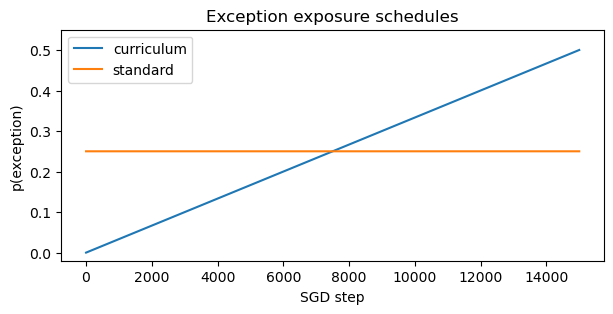


[standard] mid-schedule sample (p_exception[7500:7508] = [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25])
  is_exception    : [False False  True  True False False False False]
  y               : [1. 1. 1. 1. 0. 1. 1. 0.]
  X               :
 [[-1.7   0.93  0.63]
 [-1.22  0.84  0.91]
 [ 1.12  1.31 -1.04]
 [ 1.41  0.8  -0.89]
 [ 1.27 -0.97 -1.22]
 [-1.28 -1.14 -0.93]
 [-1.3  -1.06 -1.05]
 [ 1.16  1.06  1.11]]

[curriculum] mid-schedule sample (p_exception[7500:7508] = [0.25001666 0.25005    0.25008333 0.25011668 0.25015002 0.25018334
 0.2502167  0.25025   ])
  is_exception    : [False False  True  True False False False False]
  y               : [1. 1. 1. 1. 0. 1. 1. 0.]
  X               :
 [[-1.7   0.93  0.63]
 [-1.22  0.84  0.91]
 [ 1.12  1.31 -1.04]
 [ 1.41  0.8  -0.89]
 [ 1.27 -0.97 -1.22]
 [-1.28 -1.14 -0.93]
 [-1.3  -1.06 -1.05]
 [ 1.16  1.06  1.11]]


In [5]:
# --- Task shape + a few sampled trials, for visual sanity ---
task = make_gaussian_type5_task(noise_std=0.3)

print("input_dim    :", task.input_dim)
print("noise_std    :", task.input_noise_std)
print("x_central   :", task.x_central.shape)
print("x_peripheral:", task.x_peripheral.shape)
print()
print("Central prototype[0]  :", task.x_central[0])
print("Peripheral prototype[1]:", task.x_peripheral[1])

# --- Schedules ---
n_steps = 15000
p_curr = curriculum_prob_schedule(n_steps=n_steps, kind="curriculum",
                                  p_final=0.5, warmup_frac=0.0, ramp_frac=1.0)
p_std  = np.full(n_steps, p_curr.mean(), dtype=np.float32)

print()
print("Mean p(exception), curriculum:", p_curr.mean())
print("Mean p(exception), standard  :", p_std.mean())

plot_schedule(p_curr, p_std)

# --- A few sampled (x, y) rows from each schedule ---
mid = n_steps // 2
n_show = 8

for name, sched in [("standard", p_std), ("curriculum", p_curr)]:
    sub = sched[mid:mid + n_show]
    X, y, is_exc, item = make_trial_sequence_gaussian(task, sub, seed=0)
    X_np = X.cpu().numpy()
    print(f"\n[{name}] mid-schedule sample (p_exception[{mid}:{mid+n_show}] = {sub})")
    print("  is_exception    :", is_exc)
    print("  y               :", y.cpu().numpy())
    print("  X               :\n", np.round(X_np, 2))

## Training and evaluation

`evaluate_model_clean` computes accuracies / losses on the **clean** prototype matrix (no eval-time noise), so metrics are directly comparable across configs. `train_one_run_gaussian` is single-trial SGD over a pre-sampled trial sequence. `run_many_gaussian` loops the same over (condition × seed) and concatenates.

In [6]:
def compute_loss_from_logits(logits, y, loss_type="bce"):
    if loss_type == "bce":
        return F.binary_cross_entropy_with_logits(logits, y)
    if loss_type == "mse_sigmoid":
        return F.mse_loss(torch.sigmoid(logits), y)
    raise ValueError(f"Unknown loss_type: {loss_type}")


@torch.no_grad()
def evaluate_model_clean(model, task, loss_type="bce"):
    """Evaluate on the noise-free prototype matrix (no per-eval Gaussian noise)."""
    model.eval()
    dev = next(model.parameters()).device

    Xc = torch.as_tensor(task.x_central,    dtype=torch.float32, device=dev)
    yc = torch.as_tensor(task.y_central,    dtype=torch.float32, device=dev)
    Xp = torch.as_tensor(task.x_peripheral, dtype=torch.float32, device=dev)
    yp = torch.as_tensor(task.y_peripheral, dtype=torch.float32, device=dev)

    logits_c = model(Xc)
    logits_p = model(Xp)
    logits_all = torch.cat([logits_c, logits_p])
    y_all = torch.cat([yc, yp])

    def acc(logits, y):
        return ((logits >= 0).float() == y).float().mean().item()

    def margin(logits, y):
        return ((2 * y - 1) * logits).mean().item()

    return {
        "central_acc":       acc(logits_c, yc),
        "peripheral_acc":    acc(logits_p, yp),
        "all_acc":           acc(logits_all, y_all),
        "central_margin":    margin(logits_c, yc),
        "peripheral_margin": margin(logits_p, yp),
        "all_margin":        margin(logits_all, y_all),
        "central_loss":      compute_loss_from_logits(logits_c, yc, loss_type).item(),
        "peripheral_loss":   compute_loss_from_logits(logits_p, yp, loss_type).item(),
        "all_loss":          compute_loss_from_logits(logits_all, y_all, loss_type).item(),
    }

In [7]:
def train_one_run_gaussian(
    task,
    p_exception,
    seed=0,
    seed_id=None,
    condition="condition",
    n_hidden=4,
    init_std=0.05,
    rank=None,
    lr=0.01,
    eval_every=50,
    loss_type="bce",
    batch_size=1,
):
    """Minimal single-trial (or small-batch) SGD run on the Gaussian-input task.

    Random init only, no L1 / weight decay / grad clip / pretraining.
    Eval is on the clean prototype matrix.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = GaussianReLUNet(
        n_hidden=n_hidden,
        input_dim=task.input_dim,
        init_std=init_std,
        rank=rank,
    ).to(device)

    sid = seed if seed_id is None else seed_id

    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    X_seq, y_seq, is_exception, item_index = make_trial_sequence_gaussian(
        task=task, p_exception=p_exception, seed=seed, device=device,
    )

    rows = []
    last_loss = np.nan
    last_task_loss = np.nan
    last_is_exception = np.nan

    def record(step, recent_exception_rate=np.nan, p_value=np.nan):
        nonlocal last_loss, last_task_loss, last_is_exception
        model.eval()
        metrics = evaluate_model_clean(model, task, loss_type=loss_type)
        metrics.update({
            "condition": condition,
            "seed": sid,
            "step": step,
            "loss": last_loss,
            "task_loss": last_task_loss,
            "p_exception": p_value,
            "recent_exception_rate": recent_exception_rate,
            "last_is_exception": last_is_exception,
            "n_hidden": n_hidden,
            "init_std": init_std,
            "input_dim": task.input_dim,
            "input_noise_std": task.input_noise_std,
        })
        rows.append(metrics)
        model.train()

    n_steps = len(p_exception)
    record(step=0, p_value=float(p_exception[0]))

    model.train()
    for start in range(0, n_steps, batch_size):
        end = min(start + batch_size, n_steps)

        x = X_seq[start:end]
        y = y_seq[start:end]
        batch_is_exception = is_exception[start:end]
        last_is_exception = bool(batch_is_exception[-1])

        optimizer.zero_grad()
        logit = model(x).view(-1)
        task_loss = compute_loss_from_logits(logit, y, loss_type=loss_type)
        task_loss.backward()
        optimizer.step()

        last_loss = float(task_loss.item())
        last_task_loss = float(task_loss.item())

        if (end % eval_every == 0) or (end == n_steps):
            recent = is_exception[max(0, end - 100):end].mean()
            record(step=end,
                   recent_exception_rate=float(recent),
                   p_value=float(p_exception[end - 1]))

    return model, pd.DataFrame(rows)

In [8]:
def run_many_gaussian(task, schedules, n_seeds=5, base_seed=123, **train_kwargs):
    """Loop over conditions x seeds; return one concatenated history DataFrame."""
    all_hist = []
    for condition, p_exception in schedules.items():
        for seed_id in range(n_seeds):
            _, hist = train_one_run_gaussian(
                task=task,
                p_exception=p_exception,
                seed=base_seed + seed_id,
                seed_id=seed_id,
                condition=condition,
                **train_kwargs,
            )
            all_hist.append(hist)
    return pd.concat(all_hist, ignore_index=True)


def plot_1x4(hist, smooth_window=10, mode="standard", title_suffix=""):
    """1x4 panel: all_loss, central_loss, peripheral_loss, central+peripheral acc.
    One condition per call."""
    d = hist[hist["condition"] == mode].copy()
    metrics = ["all_loss", "central_loss", "peripheral_loss"]
    d = d.dropna(subset=metrics + ["central_acc", "peripheral_acc"])

    if smooth_window and smooth_window > 1:
        d = d.sort_values(["seed", "step"])
        for m in metrics + ["central_acc", "peripheral_acc"]:
            d[m] = d.groupby("seed")[m].transform(
                lambda x: x.rolling(smooth_window, min_periods=1).mean())

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharex=True)
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    loss_color, rule_color, exc_color = colors[0], colors[1], colors[2]

    def one_metric(ax, metric, color, title):
        for seed, ds in d.groupby("seed"):
            ds = ds.sort_values("step")
            ax.plot(ds["step"], ds[metric], color=color, alpha=0.15, linewidth=0.8)
        mean_df = d.groupby("step")[metric].mean().reset_index().sort_values("step")
        ax.plot(mean_df["step"], mean_df[metric], color=color, linewidth=3.0,
                label=f"{metric} mean")
        ax.set_title(title)
        ax.set_xlabel("SGD step")
        ax.legend(frameon=False)

    one_metric(axes[0], "all_loss",        loss_color, "All loss")
    one_metric(axes[1], "central_loss",    loss_color, "Rule / central loss")
    one_metric(axes[2], "peripheral_loss", loss_color, "Exception / peripheral loss")

    ax = axes[3]
    for metric, color, label in [
        ("central_acc",    rule_color, "rule / central"),
        ("peripheral_acc", exc_color,  "exception / peripheral"),
    ]:
        for seed, ds in d.groupby("seed"):
            ds = ds.sort_values("step")
            ax.plot(ds["step"], ds[metric], color=color, alpha=0.15, linewidth=0.8)
        mean_df = d.groupby("step")[metric].mean().reset_index().sort_values("step")
        ax.plot(mean_df["step"], mean_df[metric], color=color, linewidth=3.0, label=label)
    ax.set_title("Accuracy")
    ax.set_xlabel("SGD step")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(frameon=False)

    for i, ax in enumerate(axes):
        if i in (0, 1, 2):
            ax.set_ylim(-0.05, 1.05)
            ax.axhline(np.log(2), color="gray", linestyle="--", linewidth=1.0, alpha=0.5)
        if i == 3:
            ax.axhline(0.5, color="gray", linestyle="--", linewidth=1.0, alpha=0.5)

    axes[0].set_ylabel("Loss")
    fig.suptitle(f"{mode}{title_suffix}", y=1.02)
    plt.tight_layout()
    plt.show()

## Sweep A — σ facets × training length

**Optimisation**: standard's schedule is length-invariant, so a single 100k standard run per (facet, seed) contains the 5k / 15k / 45k checkpoints as intermediate rows (same seed → same trial sequence for the first N steps). Curriculum ramps stretch with `n_steps`, so curriculum needs a separate run per T.

In [9]:
LENGTHS_L       = [2500, 5000, 15000]
SIGMA_VALUES_L  = [0.1, 2.0, 4.0, 6.0, 8.0]
N_SEEDS_L       = 10
BASE_HIDDEN_L   = 32
BASE_INIT_STD_L = 0.05
LR_L            = 0.01
EVAL_EVERY_L    = 100

hist_L_list = []
for sig in SIGMA_VALUES_L:
    task_L = make_gaussian_type5_task(noise_std=sig)

    # Standard: one long run per seed; intermediate steps come from trajectory
    std_hist = run_many_gaussian(
        task=task_L,
        schedules={"standard": np.full(LENGTHS_L[-1], 0.25, dtype=np.float32)},
        n_seeds=N_SEEDS_L, base_seed=123,
        n_hidden=BASE_HIDDEN_L, init_std=BASE_INIT_STD_L,
        lr=LR_L, eval_every=EVAL_EVERY_L, loss_type="bce", batch_size=1,
    )
    std_hist["sigma"] = sig
    hist_L_list.append(std_hist)

    # Curriculum: one run per training length
    for T in LENGTHS_L:
        p_curr = curriculum_prob_schedule(
            n_steps=T, kind="curriculum",
            p_final=0.5, warmup_frac=0.0, ramp_frac=1.0,
        )
        curr_hist = run_many_gaussian(
            task=task_L,
            schedules={f"curriculum_T={T}": p_curr},
            n_seeds=N_SEEDS_L, base_seed=123,
            n_hidden=BASE_HIDDEN_L, init_std=BASE_INIT_STD_L,
            lr=LR_L, eval_every=EVAL_EVERY_L, loss_type="bce", batch_size=1,
        )
        curr_hist["sigma"] = sig
        hist_L_list.append(curr_hist)
    print(f"σ = {sig} done")

hist_L = pd.concat(hist_L_list, ignore_index=True)

# --- Extract final metrics per (σ, T, condition) ---
rows = []
for sig in SIGMA_VALUES_L:
    d_sig = hist_L[hist_L["sigma"] == sig]
    for T in LENGTHS_L:
        std_at_T  = d_sig[(d_sig["condition"] == "standard")            & (d_sig["step"] == T)]
        curr_at_T = d_sig[(d_sig["condition"] == f"curriculum_T={T}")   & (d_sig["step"] == T)]
        for label, dset in [("standard", std_at_T), ("curriculum", curr_at_T)]:
            rows.append(dict(
                sigma=sig, T=T, condition=label,
                periph_acc=dset["peripheral_acc"].mean(),
                periph_sem=dset["peripheral_acc"].sem(),
                periph_loss=dset["peripheral_loss"].mean(),
                central_acc=dset["central_acc"].mean(),
                central_sem=dset["central_acc"].sem(),
            ))
summary_L = pd.DataFrame(rows)

# --- Plot: 2×N_σ facets, top = peripheral_acc, bottom = central (rule) acc ---
n_sigs = len(SIGMA_VALUES_L)
fig, axes = plt.subplots(2, n_sigs, figsize=(4.2 * n_sigs, 8.5), sharey=True, sharex=True)
if n_sigs == 1:
    axes = axes.reshape(2, 1)

for col, sig in enumerate(SIGMA_VALUES_L):
    d_sig = summary_L[summary_L["sigma"] == sig]
    for row_idx, (acc_col, sem_col, ylabel) in enumerate([
        ("periph_acc",  "periph_sem",  "final peripheral_acc"),
        ("central_acc", "central_sem", "final central (rule) acc"),
    ]):
        ax = axes[row_idx, col]
        for cond in ["standard", "curriculum"]:
            dc = d_sig[d_sig["condition"] == cond].sort_values("T")
            ax.errorbar(dc["T"], dc[acc_col],
                        yerr=dc[sem_col].fillna(0),
                        marker="o", label=cond, capsize=3, linewidth=1.6, markersize=8)
        ax.set_xscale("log")
        ax.set_ylim(-0.05, 1.05)
        ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)
        if row_idx == 0:
            ax.set_title(f"σ = {sig}")
        if row_idx == 1:
            ax.set_xlabel("training length (steps)")
        if col == 0:
            ax.set_ylabel(ylabel)
        ax.legend(fontsize=9, frameon=False, loc="lower right")

plt.suptitle(f"Standard vs curriculum(ramp=1.0)  —  matched total exception exposure  "
             f"(K = {BASE_HIDDEN_L})",
             y=1.00, fontsize=11)
plt.tight_layout()
plt.show()

print("\nFinal metrics by (σ, T, condition):")
print(summary_L.round(3).to_string(index=False))

KeyboardInterrupt: 

## Sweep B — K facets × training length

K = 4 done
K = 16 done
K = 64 done
K = 256 done
K = 1024 done


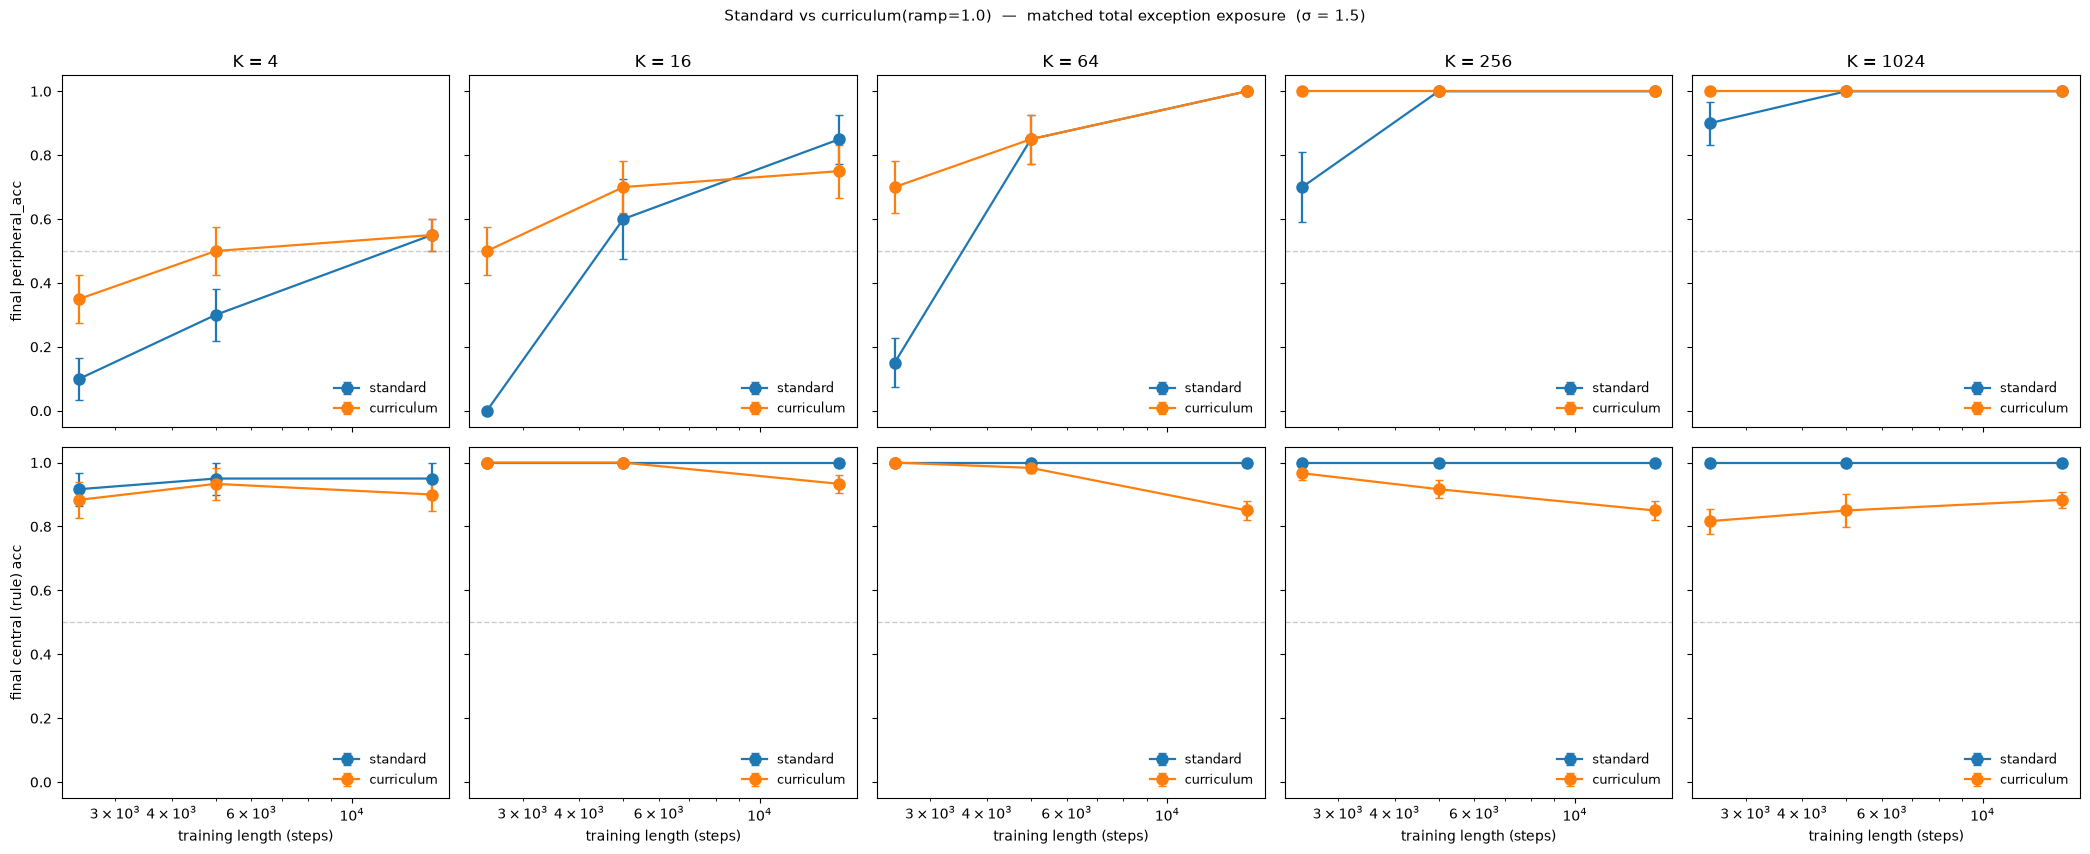


Final metrics by (K, T, condition):
   K     T  condition  periph_acc  periph_sem  periph_loss  central_acc  central_sem
   4  2500   standard        0.10       0.067        0.738        0.917        0.051
   4  2500 curriculum        0.35       0.076        0.696        0.883        0.056
   4  5000   standard        0.30       0.082        0.710        0.950        0.050
   4  5000 curriculum        0.50       0.075        0.693        0.933        0.051
   4 15000   standard        0.55       0.050        0.693        0.950        0.050
   4 15000 curriculum        0.55       0.050        0.693        0.900        0.051
  16  2500   standard        0.00       0.000        0.750        1.000        0.000
  16  2500 curriculum        0.50       0.075        0.693        1.000        0.000
  16  5000   standard        0.60       0.125        0.695        1.000        0.000
  16  5000 curriculum        0.70       0.082        0.692        1.000        0.000
  16 15000   standard       

In [103]:
LENGTHS_LK       = [2500, 5000, 15000]
K_VALUES_LK      = [4, 16, 64, 256, 1024]
FIXED_SIGMA_LK   = 1.5
N_SEEDS_LK       = 10
BASE_INIT_STD_LK = 0.05
LR_LK            = 0.01
EVAL_EVERY_LK    = 100

hist_LK_list = []
for K in K_VALUES_LK:
    task_LK = make_gaussian_type5_task(noise_std=FIXED_SIGMA_LK)

    # Standard: one long run per seed
    std_hist = run_many_gaussian(
        task=task_LK,
        schedules={"standard": np.full(LENGTHS_LK[-1], 0.25, dtype=np.float32)},
        n_seeds=N_SEEDS_LK, base_seed=123,
        n_hidden=K, init_std=BASE_INIT_STD_LK,
        lr=LR_LK, eval_every=EVAL_EVERY_LK, loss_type="bce", batch_size=1,
    )
    std_hist["K"] = K
    hist_LK_list.append(std_hist)

    # Curriculum: one run per length
    for T in LENGTHS_LK:
        p_curr = curriculum_prob_schedule(
            n_steps=T, kind="curriculum",
            p_final=0.5, warmup_frac=0.0, ramp_frac=1.0,
        )
        curr_hist = run_many_gaussian(
            task=task_LK,
            schedules={f"curriculum_T={T}": p_curr},
            n_seeds=N_SEEDS_LK, base_seed=123,
            n_hidden=K, init_std=BASE_INIT_STD_LK,
            lr=LR_LK, eval_every=EVAL_EVERY_LK, loss_type="bce", batch_size=1,
        )
        curr_hist["K"] = K
        hist_LK_list.append(curr_hist)
    print(f"K = {K} done")

hist_LK = pd.concat(hist_LK_list, ignore_index=True)

# --- Extract final metrics per (K, T, condition) ---
rows = []
for K in K_VALUES_LK:
    d_K = hist_LK[hist_LK["K"] == K]
    for T in LENGTHS_LK:
        std_at_T  = d_K[(d_K["condition"] == "standard")           & (d_K["step"] == T)]
        curr_at_T = d_K[(d_K["condition"] == f"curriculum_T={T}")  & (d_K["step"] == T)]
        for label, dset in [("standard", std_at_T), ("curriculum", curr_at_T)]:
            rows.append(dict(
                K=K, T=T, condition=label,
                periph_acc=dset["peripheral_acc"].mean(),
                periph_sem=dset["peripheral_acc"].sem(),
                periph_loss=dset["peripheral_loss"].mean(),
                central_acc=dset["central_acc"].mean(),
                central_sem=dset["central_acc"].sem(),
            ))
summary_LK = pd.DataFrame(rows)

# --- Plot: 2×N_K facets, top = peripheral_acc, bottom = central (rule) acc ---
n_ks = len(K_VALUES_LK)
fig, axes = plt.subplots(2, n_ks, figsize=(4.2 * n_ks, 8.5), sharey=True, sharex=True)
if n_ks == 1:
    axes = axes.reshape(2, 1)

for col, K in enumerate(K_VALUES_LK):
    d_K = summary_LK[summary_LK["K"] == K]
    for row_idx, (acc_col, sem_col, ylabel) in enumerate([
        ("periph_acc",  "periph_sem",  "final peripheral_acc"),
        ("central_acc", "central_sem", "final central (rule) acc"),
    ]):
        ax = axes[row_idx, col]
        for cond in ["standard", "curriculum"]:
            dc = d_K[d_K["condition"] == cond].sort_values("T")
            ax.errorbar(dc["T"], dc[acc_col],
                        yerr=dc[sem_col].fillna(0),
                        marker="o", label=cond, capsize=3, linewidth=1.6, markersize=8)
        ax.set_xscale("log")
        ax.set_ylim(-0.05, 1.05)
        ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)
        if row_idx == 0:
            ax.set_title(f"K = {K}")
        if row_idx == 1:
            ax.set_xlabel("training length (steps)")
        if col == 0:
            ax.set_ylabel(ylabel)
        ax.legend(fontsize=9, frameon=False, loc="lower right")

plt.suptitle(f"Standard vs curriculum(ramp=1.0)  —  matched total exception exposure  "
             f"(σ = {FIXED_SIGMA_LK})",
             y=1.00, fontsize=11)
plt.tight_layout()
plt.show()

print("\nFinal metrics by (K, T, condition):")
print(summary_LK.round(3).to_string(index=False))

## Sweep C — rank / participation-ratio facets × training length

Init sanity (K=512):
  requested rank=   1  ->  empirical rank=   1, PR(W)=1.00, ‖W‖_F=1.1314
  requested rank=   2  ->  empirical rank=   2, PR(W)=2.00, ‖W‖_F=1.1314
  requested rank=   3  ->  empirical rank=   3, PR(W)=2.99, ‖W‖_F=1.1638
rank = 1 done
rank = 2 done
rank = 3 done


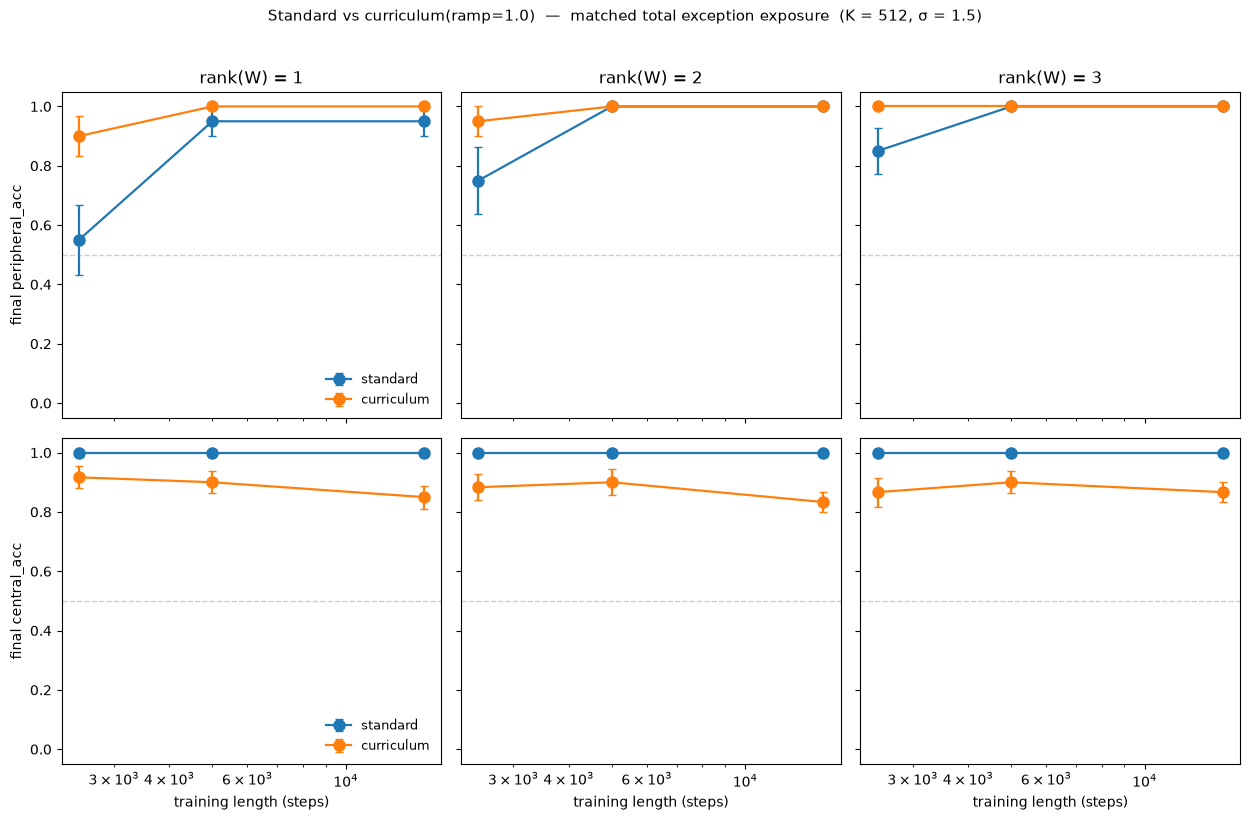


Final metrics by (rank, T, condition):
 rank     T  condition  periph_acc  periph_sem  periph_loss  central_acc  central_sem
    1  2500   standard        0.55       0.117        0.674        1.000        0.000
    1  2500 curriculum        0.90       0.067        0.607        0.917        0.037
    1  5000   standard        0.95       0.050        0.643        1.000        0.000
    1  5000 curriculum        1.00       0.000        0.594        0.900        0.037
    1 15000   standard        0.95       0.050        0.635        1.000        0.000
    1 15000 curriculum        1.00       0.000        0.521        0.850        0.039
    2  2500   standard        0.75       0.112        0.669        1.000        0.000
    2  2500 curriculum        0.95       0.050        0.582        0.883        0.043
    2  5000   standard        1.00       0.000        0.624        1.000        0.000
    2  5000 curriculum        1.00       0.000        0.560        0.900        0.044
    2 15000   

In [104]:
# --- Sweep C: standard vs curriculum(ramp=1.0), rank facets × training length ---
# Facet by rank of W at init.
# Same "standard reused across lengths" optimization as Sweeps A/B.

RANK_VALUES     = [1, 2, 3]
LENGTHS_C       = [2500, 5000, 15000]
FIXED_K_C       = 512
FIXED_SIGMA_C   = 1.5
N_SEEDS_C       = 10
LR_C            = 0.01
EVAL_EVERY_C    = 100

# --- Sanity: verify rank/PR/norm of the low-rank init before running the sweep ---
print(f"Init sanity (K={FIXED_K_C}):")
for r in RANK_VALUES:
    torch.manual_seed(0)
    net = GaussianReLUNet(n_hidden=FIXED_K_C, input_dim=INPUT_DIM, rank=r)
    W = net.W.detach()
    sv = torch.linalg.svdvals(W)
    empirical_rank = int((sv > 1e-6).sum())
    pr = ((sv**2).sum()**2 / (sv**4).sum()).item()
    print(f"  requested rank={r:4d}  ->  empirical rank={empirical_rank:4d}, "
          f"PR(W)={pr:.2f}, ‖W‖_F={W.norm():.4f}")

# --- Run the sweep ---
hist_C_list = []
for r in RANK_VALUES:
    task_C = make_gaussian_type5_task(noise_std=FIXED_SIGMA_C)

    # Standard: one long run per seed; intermediate steps read from trajectory
    std_hist = run_many_gaussian(
        task=task_C,
        schedules={"standard": np.full(LENGTHS_C[-1], 0.25, dtype=np.float32)},
        n_seeds=N_SEEDS_C, base_seed=123,
        n_hidden=FIXED_K_C, rank=r,
        lr=LR_C, eval_every=EVAL_EVERY_C, loss_type="bce", batch_size=1,
    )
    std_hist["rank"] = r
    hist_C_list.append(std_hist)

    # Curriculum: one run per training length
    for T in LENGTHS_C:
        p_curr = curriculum_prob_schedule(
            n_steps=T, kind="curriculum",
            p_final=0.5, warmup_frac=0.0, ramp_frac=1.0,
        )
        curr_hist = run_many_gaussian(
            task=task_C,
            schedules={f"curriculum_T={T}": p_curr},
            n_seeds=N_SEEDS_C, base_seed=123,
            n_hidden=FIXED_K_C, rank=r,
            lr=LR_C, eval_every=EVAL_EVERY_C, loss_type="bce", batch_size=1,
        )
        curr_hist["rank"] = r
        hist_C_list.append(curr_hist)
    print(f"rank = {r} done")

hist_C = pd.concat(hist_C_list, ignore_index=True)

# --- Extract final metrics per (rank, T, condition) ---
rows = []
for r in RANK_VALUES:
    d_r = hist_C[hist_C["rank"] == r]
    for T in LENGTHS_C:
        std_at_T  = d_r[(d_r["condition"] == "standard")           & (d_r["step"] == T)]
        curr_at_T = d_r[(d_r["condition"] == f"curriculum_T={T}")  & (d_r["step"] == T)]
        rows.append(dict(
            rank=r, T=T, condition="standard",
            periph_acc=std_at_T["peripheral_acc"].mean(),
            periph_sem=std_at_T["peripheral_acc"].sem(),
            periph_loss=std_at_T["peripheral_loss"].mean(),
            central_acc=std_at_T["central_acc"].mean(),
            central_sem=std_at_T["central_acc"].sem(),
        ))
        rows.append(dict(
            rank=r, T=T, condition="curriculum",
            periph_acc=curr_at_T["peripheral_acc"].mean(),
            periph_sem=curr_at_T["peripheral_acc"].sem(),
            periph_loss=curr_at_T["peripheral_loss"].mean(),
            central_acc=curr_at_T["central_acc"].mean(),
            central_sem=curr_at_T["central_acc"].sem(),
        ))
summary_C = pd.DataFrame(rows)

# --- Plot: 2 x N_rank facets. Top row: peripheral_acc; bottom row: central_acc ---
n_ranks = len(RANK_VALUES)
fig, axes = plt.subplots(2, n_ranks, figsize=(4.2 * n_ranks, 8),
                          sharey="row", sharex="col")
if n_ranks == 1:
    axes = axes.reshape(2, 1)

for col_i, r in enumerate(RANK_VALUES):
    d_r = summary_C[summary_C["rank"] == r]
    ax_p = axes[0, col_i]
    ax_c = axes[1, col_i]
    for cond in ["standard", "curriculum"]:
        dc = d_r[d_r["condition"] == cond].sort_values("T")
        ax_p.errorbar(dc["T"], dc["periph_acc"],
                      yerr=dc["periph_sem"].fillna(0),
                      marker="o", label=cond, capsize=3, linewidth=1.6, markersize=8)
        ax_c.errorbar(dc["T"], dc["central_acc"],
                      yerr=dc["central_sem"].fillna(0),
                      marker="o", label=cond, capsize=3, linewidth=1.6, markersize=8)
    ax_p.set_xscale("log"); ax_c.set_xscale("log")
    ax_p.set_title(f"rank(W) = {r}")
    ax_p.set_ylim(-0.05, 1.05); ax_c.set_ylim(-0.05, 1.05)
    ax_p.axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)
    ax_c.axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)
    ax_c.set_xlabel("training length (steps)")
    if col_i == 0:
        ax_p.set_ylabel("final peripheral_acc")
        ax_c.set_ylabel("final central_acc")
        ax_p.legend(fontsize=9, frameon=False, loc="lower right")
        ax_c.legend(fontsize=9, frameon=False, loc="lower right")

plt.suptitle(f"Standard vs curriculum(ramp=1.0)  —  matched total exception exposure  "
             f"(K = {FIXED_K_C}, σ = {FIXED_SIGMA_C})",
             y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

print("\nFinal metrics by (rank, T, condition):")
print(summary_C.round(3).to_string(index=False))

## Pretraining: 1-d rule vs XOR → type-5 transfer

**Question.** Does *what the network learned first* change how it later handles rule + exception structure, and does that interact with the curriculum effect? Sweep C imposed low-dimensional structure through the **init**; here the structure is **learned**, by pretraining on one of two tasks in the same R³ input space (same model, optimizer, loss):

- **1d** — label = sign of a single feature; the feature is chosen at random per run, so any dim can carry the rule.
- **xor** — label = XOR of the signs of two features; the pair is chosen at random per run.

**Parameterizable**: `noise_std` (isotropic Gaussian noise added to the clean signal — labels always come from the clean signal, exactly as in the type-5 task) and `input_dist` (the training distribution of the clean signal: `"hypercube"` = uniform over the 8 corners of {−1,+1}³, or `"gaussian"` = N(0, I₃)).

**Prediction for PR(W).** Random init at K ≫ 3 has PR(W) ≈ 3. A converged 1-d solution needs one input direction (PR → 1); XOR needs two (PR → 2). So pretraining is a learned analogue of Sweep C's rank-r init.

Two analyses, in order: **(1)** PR(W) as a function of pretraining length, **(2)** pick one pretraining length (`T_PRE`) from that curve and compare type-5 fine-tuning under standard vs curriculum (σ = 1.5, K = 256).

In [107]:
# ── Pretraining tasks: 1-d rule vs XOR ───────────────────────────────────────
# Same R^3 input space, model, optimizer, and loss as the type-5 runs.
# The relevant feature(s) are chosen at random per run, so any dim can carry
# the rule. Noise level and the training input distribution are parameters.

PRETRAIN_KINDS = ("1d", "xor")


def sample_pretrain_features(kind, rng):
    """Random feature indices carrying the pretraining rule."""
    if kind == "1d":
        return (int(rng.integers(0, INPUT_DIM)),)
    if kind == "xor":
        i, j = rng.choice(INPUT_DIM, size=2, replace=False)
        return (int(i), int(j))
    raise ValueError(f"Unknown pretrain kind: {kind}")


def pretrain_labels(x_signal, kind, features):
    """Label from the *clean* signal (before noise), so noise_std acts exactly
    like the type-5 task's input noise. x_signal: (n, d)."""
    if kind == "1d":
        (i,) = features
        return (x_signal[:, i] > 0).astype(np.float32)
    if kind == "xor":
        i, j = features
        return ((x_signal[:, i] > 0) != (x_signal[:, j] > 0)).astype(np.float32)
    raise ValueError(f"Unknown pretrain kind: {kind}")


def make_pretrain_sequence(kind, features, n_steps, noise_std=1.5,
                           input_dist="hypercube", seed=0, device=None):
    """Sample a pretraining trial sequence.

    input_dist — the training distribution of the clean signal:
      - "hypercube": uniform over the 8 corners of {-1,+1}^3 (matches type-5 style)
      - "gaussian":  x_signal ~ N(0, I_3)
    Observed input = clean signal + N(0, noise_std² I_3).
    """
    rng = np.random.default_rng(seed)
    d = INPUT_DIM
    if input_dist == "hypercube":
        x_signal = rng.choice([-1.0, 1.0], size=(n_steps, d)).astype(np.float32)
    elif input_dist == "gaussian":
        x_signal = rng.standard_normal((n_steps, d)).astype(np.float32)
    else:
        raise ValueError(f"Unknown input_dist: {input_dist}")

    y = pretrain_labels(x_signal, kind, features)
    X = x_signal + rng.standard_normal((n_steps, d)).astype(np.float32) * noise_std

    X = torch.as_tensor(X, dtype=torch.float32, device=device)
    y = torch.as_tensor(y, dtype=torch.float32, device=device)
    return X, y


def participation_ratio(model):
    """PR of the singular-value spectrum of W: (Σσ²)² / Σσ⁴ ∈ [1, min(K, d)]."""
    with torch.no_grad():
        sv = torch.linalg.svdvals(model.W.detach())
        return ((sv**2).sum()**2 / (sv**4).sum()).item()


ALL_CORNERS = (np.array([[(c >> k) & 1 for k in range(INPUT_DIM)]
                         for c in range(2**INPUT_DIM)], dtype=np.float32) * 2 - 1)


@torch.no_grad()
def evaluate_pretrain_clean(model, kind, features):
    """Accuracy on the 8 clean hypercube corners under the pretraining rule."""
    dev = next(model.parameters()).device
    X = torch.as_tensor(ALL_CORNERS, dtype=torch.float32, device=dev)
    y = torch.as_tensor(pretrain_labels(ALL_CORNERS, kind, features), device=dev)
    logits = model(X)
    return ((logits >= 0).float() == y).float().mean().item()


def pretrain_model(
    kind, seed=0, n_steps=20000, noise_std=1.5, input_dist="hypercube",
    n_hidden=256, init_std=0.05, lr=0.01, eval_every=200, loss_type="bce",
    checkpoint_steps=(),
):
    """Online single-trial SGD on a pretraining task.

    Returns (model, history, checkpoints, features); `checkpoints` maps
    step -> state_dict copy (include 0 to snapshot the random init).
    History records loss, clean-corner accuracy, and PR(W) every eval_every.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    features = sample_pretrain_features(kind, np.random.default_rng(seed))

    model = GaussianReLUNet(n_hidden=n_hidden, input_dim=INPUT_DIM,
                            init_std=init_std).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    X_seq, y_seq = make_pretrain_sequence(
        kind, features, n_steps, noise_std=noise_std,
        input_dist=input_dist, seed=seed, device=device,
    )

    checkpoint_steps = set(checkpoint_steps)
    checkpoints = {}

    def snapshot(step):
        checkpoints[step] = {k: v.detach().clone()
                             for k, v in model.state_dict().items()}

    rows = []
    last_loss = np.nan

    def record(step):
        rows.append(dict(
            kind=kind, seed=seed, step=step, loss=last_loss,
            clean_acc=evaluate_pretrain_clean(model, kind, features),
            pr=participation_ratio(model),
            features=str(features), noise_std=noise_std, input_dist=input_dist,
        ))

    if 0 in checkpoint_steps:
        snapshot(0)
    record(0)

    model.train()
    for t in range(n_steps):
        optimizer.zero_grad()
        logit = model(X_seq[t:t+1]).view(-1)
        loss = compute_loss_from_logits(logit, y_seq[t:t+1], loss_type=loss_type)
        loss.backward()
        optimizer.step()
        last_loss = float(loss.item())

        step = t + 1
        if step in checkpoint_steps:
            snapshot(step)
        if (step % eval_every == 0) or (step == n_steps):
            record(step)

    return model, pd.DataFrame(rows), checkpoints, features


# --- Sanity: random features + labels on the corners ---
rng_demo = np.random.default_rng(0)
print("sampled 1d features :", [sample_pretrain_features("1d", rng_demo) for _ in range(5)])
print("sampled xor features:", [sample_pretrain_features("xor", rng_demo) for _ in range(3)])
print("\ncorners | 1d(feature 1) | xor(0, 2):")
print(np.column_stack([ALL_CORNERS,
                       pretrain_labels(ALL_CORNERS, "1d", (1,)),
                       pretrain_labels(ALL_CORNERS, "xor", (0, 2))]))

sampled 1d features : [(2,), (1,), (1,), (0,), (0,)]
sampled xor features: [(2, 0), (0, 2), (1, 2)]

corners | 1d(feature 1) | xor(0, 2):
[[-1. -1. -1.  0.  0.]
 [ 1. -1. -1.  0.  1.]
 [-1.  1. -1.  1.  0.]
 [ 1.  1. -1.  1.  1.]
 [-1. -1.  1.  0.  1.]
 [ 1. -1.  1.  0.  0.]
 [-1.  1.  1.  1.  1.]
 [ 1.  1.  1.  1.  0.]]


### PR(W) vs pretraining length

Both tasks are learned to 100% clean-corner accuracy within ~2k steps at σ = 1.5, but PR keeps compressing well after accuracy saturates — so pretraining length matters beyond "did it learn". Reference lines at PR = 1 / 2 / 3.

pretrain kind = 1d done
pretrain kind = xor done


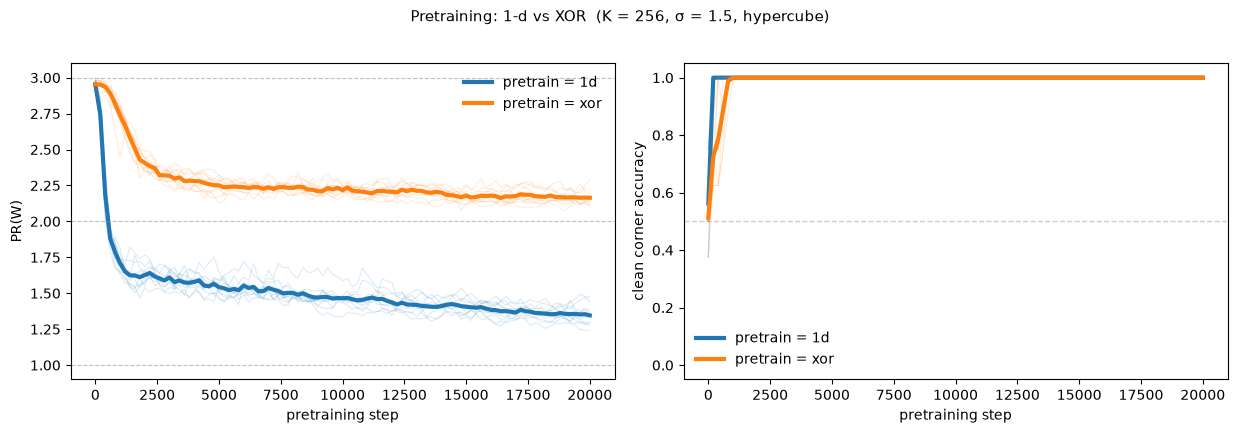


PR(W) by (kind, step):
             mean    sem
kind step               
1d   0      2.954  0.011
     1000   1.709  0.018
     4000   1.579  0.016
     20000  1.346  0.023
xor  0      2.954  0.011
     1000   2.736  0.035
     4000   2.280  0.016
     20000  2.164  0.018


In [108]:
# ── PR(W) as a function of pretraining length ────────────────────────────────
# One long run per (kind, seed): PR and clean-corner accuracy are recorded along
# the trajectory, so a single run traces the whole length axis.

K_PT          = 256
SIGMA_PT      = 1.5           # gaussian noise in the pretraining problems
INPUT_DIST_PT = "hypercube"   # training distribution of the clean signal
T_PRE_MAX     = 20000
N_SEEDS_PT    = 10
INIT_STD_PT   = 0.05
LR_PT         = 0.01
EVAL_EVERY_PT = 200

pre_hist_list = []
for kind in PRETRAIN_KINDS:
    for s in range(N_SEEDS_PT):
        _, h, _, _ = pretrain_model(
            kind, seed=123 + s, n_steps=T_PRE_MAX, noise_std=SIGMA_PT,
            input_dist=INPUT_DIST_PT, n_hidden=K_PT, init_std=INIT_STD_PT,
            lr=LR_PT, eval_every=EVAL_EVERY_PT,
        )
        h["seed_id"] = s
        pre_hist_list.append(h)
    print(f"pretrain kind = {kind} done")
pre_hist = pd.concat(pre_hist_list, ignore_index=True)

# --- Plot: PR(W) and clean accuracy vs pretraining step ---
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
kind_colors = {"1d": colors[0], "xor": colors[1]}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, metric, ylabel in [(axes[0], "pr", "PR(W)"),
                           (axes[1], "clean_acc", "clean corner accuracy")]:
    for kind in PRETRAIN_KINDS:
        d = pre_hist[pre_hist["kind"] == kind]
        for s, ds in d.groupby("seed_id"):
            ds = ds.sort_values("step")
            ax.plot(ds["step"], ds[metric], color=kind_colors[kind],
                    alpha=0.15, linewidth=0.8)
        m = d.groupby("step")[metric].mean()
        ax.plot(m.index, m.values, color=kind_colors[kind], linewidth=3.0,
                label=f"pretrain = {kind}")
    ax.set_xlabel("pretraining step")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False)

for ref in (1, 2, 3):
    axes[0].axhline(ref, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
axes[0].set_ylim(0.9, 3.1)
axes[1].set_ylim(-0.05, 1.05)
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)

plt.suptitle(f"Pretraining: 1-d vs XOR  (K = {K_PT}, σ = {SIGMA_PT}, {INPUT_DIST_PT})",
             y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

print("\nPR(W) by (kind, step):")
pr_tab = (pre_hist[pre_hist["step"].isin([0, 1000, 4000, 20000])]
          .groupby(["kind", "step"])["pr"].agg(["mean", "sem"]))
print(pr_tab.round(3).to_string())

### Pretrain → type-5: standard vs curriculum

Per (kind, seed): pretrain for `T_PRE` steps (picked from the PR curve above), then fine-tune on the type-5 task under both schedules (σ = 1.5, K = 256, T = 15000, matching Sweep B; standard = constant 0.25, curriculum = ramp 0 → 0.5). The step-0 checkpoint is the shared random init → the **none** baseline, run once. `overlaps_rule` records whether the pretraining features happened to include the downstream rule feature (feature 0).

In [109]:
def finetune_run_gaussian(
    state_dict, task, p_exception, seed=0, seed_id=None, condition="condition",
    n_hidden=256, init_std=0.05, lr=0.01, eval_every=100, loss_type="bce",
    extra_cols=None,
):
    """train_one_run_gaussian, but starting from a pretrained state_dict and
    also recording PR(W) at every eval. Trial-sequence seeding matches the
    base function, so runs are directly comparable to the from-scratch sweeps."""
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = GaussianReLUNet(n_hidden=n_hidden, input_dim=task.input_dim,
                            init_std=init_std).to(device)
    model.load_state_dict(state_dict)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    X_seq, y_seq, is_exception, item_index = make_trial_sequence_gaussian(
        task=task, p_exception=p_exception, seed=seed, device=device,
    )

    sid = seed if seed_id is None else seed_id
    rows = []
    last_loss = np.nan

    def record(step, p_value=np.nan):
        model.eval()
        metrics = evaluate_model_clean(model, task, loss_type=loss_type)
        metrics.update({
            "condition": condition, "seed": sid, "step": step, "loss": last_loss,
            "p_exception": p_value, "pr": participation_ratio(model),
            "n_hidden": n_hidden, "input_noise_std": task.input_noise_std,
        })
        if extra_cols:
            metrics.update(extra_cols)
        rows.append(metrics)
        model.train()

    n_steps = len(p_exception)
    record(step=0, p_value=float(p_exception[0]))

    model.train()
    for t in range(n_steps):
        optimizer.zero_grad()
        logit = model(X_seq[t:t+1]).view(-1)
        task_loss = compute_loss_from_logits(logit, y_seq[t:t+1], loss_type=loss_type)
        task_loss.backward()
        optimizer.step()
        last_loss = float(task_loss.item())

        step = t + 1
        if (step % eval_every == 0) or (step == n_steps):
            record(step=step, p_value=float(p_exception[step - 1]))

    return model, pd.DataFrame(rows)

In [ ]:
# ── Pretrain → type-5: standard vs curriculum after each pretraining kind ────
# Per (kind, seed): pretrain for T_PRE steps, then fine-tune under both
# schedules. The step-0 checkpoint is the shared random init (identical across
# kinds at the same seed) -> "none" baseline, run once.

T_PRE         = 5000     # pretraining length (picked from the PR curve above)
T_FT          = 2500    # type-5 training length
SIGMA_FT      = 1.5
K_FT          = 256
INIT_STD_FT   = 0.05
LR_FT         = 0.01
N_SEEDS_FT    = 100
EVAL_EVERY_FT = 100

task_FT   = make_gaussian_type5_task(noise_std=SIGMA_FT)
p_std_FT  = np.full(T_FT, 0.25, dtype=np.float32)
p_curr_FT = curriculum_prob_schedule(n_steps=T_FT, kind="curriculum",
                                     p_final=0.5, warmup_frac=0.0, ramp_frac=1.0)
SCHEDULES_FT = {"standard": p_std_FT, "curriculum": p_curr_FT}

ft_hist_list = []
for kind in PRETRAIN_KINDS:
    for s in range(N_SEEDS_FT):
        _, _, ckpts, feats = pretrain_model(
            kind, seed=123 + s, n_steps=T_PRE, noise_std=SIGMA_PT,
            input_dist=INPUT_DIST_PT, n_hidden=K_FT, init_std=INIT_STD_FT,
            lr=LR_FT, eval_every=T_PRE, checkpoint_steps=[0, T_PRE],
        )
        # run the T_pre = 0 baseline only once (under the first kind)
        starts = ([("none", 0)] if kind == PRETRAIN_KINDS[0] else []) + [(kind, T_PRE)]
        for pk, T_pre in starts:
            for sched_name, p_exc in SCHEDULES_FT.items():
                _, h = finetune_run_gaussian(
                    ckpts[T_pre], task_FT, p_exc,
                    seed=123 + s, seed_id=s, condition=sched_name,
                    n_hidden=K_FT, init_std=INIT_STD_FT, lr=LR_FT,
                    eval_every=EVAL_EVERY_FT,
                    extra_cols=dict(
                        pretrain_kind=pk, T_pre=T_pre,
                        pretrain_features=str(feats) if T_pre > 0 else "",
                        overlaps_rule=bool(T_pre > 0 and 0 in feats),
                    ),
                )
                ft_hist_list.append(h)
    print(f"pretrain kind = {kind}: finetunes done")
ft_hist = pd.concat(ft_hist_list, ignore_index=True)

# --- Final metrics per (pretrain, condition) ---
final_ft = ft_hist[ft_hist["step"] == T_FT]
start_ft = ft_hist[ft_hist["step"] == 0]
rows = []
for pk in ["none"] + list(PRETRAIN_KINDS):
    for cond in SCHEDULES_FT:
        dset  = final_ft[(final_ft["pretrain_kind"] == pk)
                         & (final_ft["condition"] == cond)]
        dset0 = start_ft[(start_ft["pretrain_kind"] == pk)
                         & (start_ft["condition"] == cond)]
        rows.append(dict(
            pretrain=pk, condition=cond,
            periph_acc=dset["peripheral_acc"].mean(),
            periph_sem=dset["peripheral_acc"].sem(),
            central_acc=dset["central_acc"].mean(),
            central_sem=dset["central_acc"].sem(),
            pr_start=dset0["pr"].mean(),
            pr_final=dset["pr"].mean(),
        ))
summary_FT = pd.DataFrame(rows)

pretrain kind = 1d: finetunes done
pretrain kind = xor: finetunes done


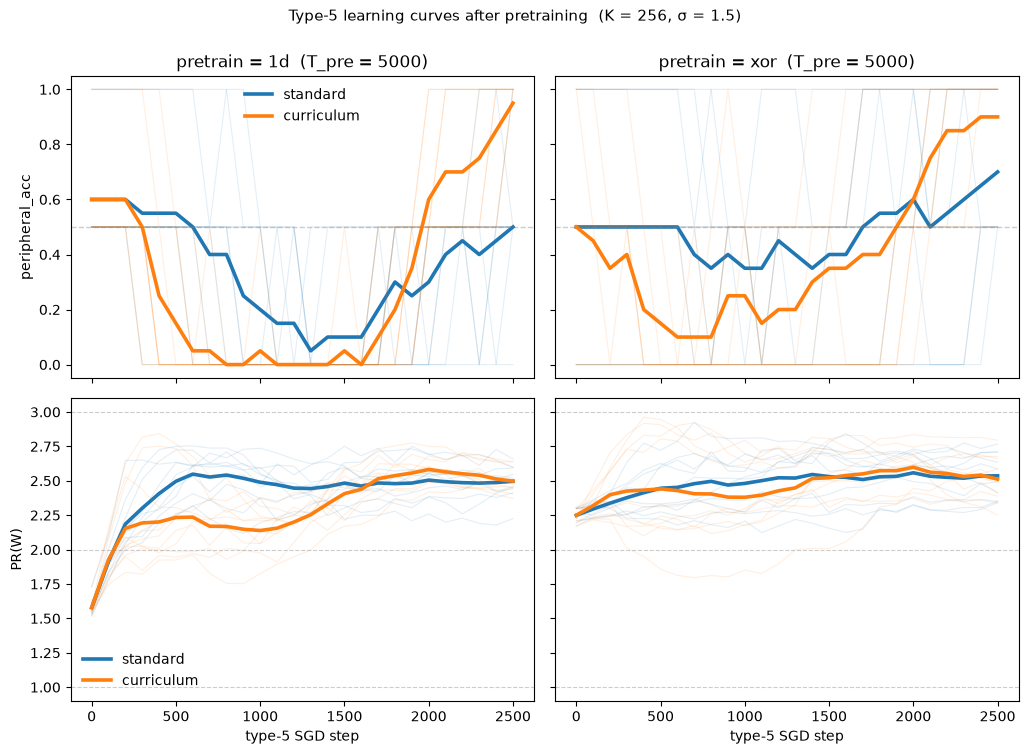

In [116]:
# ── Learning curves during type-5 training, by pretraining condition ─────────
# Peripheral accuracy and PR(W) trajectories after T_PRE steps of pretraining.

show = [("1d", T_PRE), ("xor", T_PRE)]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cond_colors = {"standard": colors[0], "curriculum": colors[1]}

fig, axes = plt.subplots(2, len(show), figsize=(5.2 * len(show), 7.5),
                         sharex=True, sharey="row")
for col, (pk, T_pre) in enumerate(show):
    d_pk = ft_hist[(ft_hist["pretrain_kind"] == pk) & (ft_hist["T_pre"] == T_pre)]
    for row_idx, (metric, ylabel) in enumerate([("peripheral_acc", "peripheral_acc"),
                                                ("pr", "PR(W)")]):
        ax = axes[row_idx, col]
        for cond in ["standard", "curriculum"]:
            d = d_pk[d_pk["condition"] == cond]
            for s, ds in d.groupby("seed"):
                ds = ds.sort_values("step")
                ax.plot(ds["step"], ds[metric], color=cond_colors[cond],
                        alpha=0.12, linewidth=0.8)
            m = d.groupby("step")[metric].mean()
            ax.plot(m.index, m.values, color=cond_colors[cond], linewidth=2.6,
                    label=cond)
        if row_idx == 0:
            ax.set_title(f"pretrain = {pk}  (T_pre = {T_pre})")
            ax.set_ylim(-0.05, 1.05)
            ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, alpha=0.4)
        else:
            ax.set_ylim(0.9, 3.1)
            for ref in (1, 2, 3):
                ax.axhline(ref, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
            ax.set_xlabel("type-5 SGD step")
        if col == 0:
            ax.set_ylabel(ylabel)
            ax.legend(frameon=False, loc="best")

plt.suptitle(f"Type-5 learning curves after pretraining  (K = {K_FT}, σ = {SIGMA_FT})",
             y=1.0, fontsize=11)
plt.tight_layout()
plt.show()

# Why does curriculum help? — H1 / H2 / H3

The sweeps above show *that* back-loading exception exposure helps peripheral generalisation under input noise. This section asks **why**, separating three mechanisms the ramp confounds:

- **H1 — distribution tracking / boundary shift.** Online SGD under noise never converges; it tracks the recent data distribution. With σ large the prototype clouds overlap, so the *Bayes-optimal* decision at a clean prototype depends on the mixture weights: raising p(exception) can flip the optimal label at the exception prototypes. Curriculum would then "help" without any better learning — its endpoint distribution simply asks for the exceptions.
- **H2 — retention / interference.** Exceptions learned early are overwritten by later rule-heavy training; back-loading works because exposure sits next to evaluation.
- **H3 — representation readiness / expansion.** With small init the early network cannot encode the interaction structure exceptions require; exposure only "sticks" once the rule scaffold exists. Curriculum works by placing exposure where the network can use it.

Tests, in order: an **ideal-observer** analysis (H1, no training needed); six **schedule controls** that unconfound endpoint distribution, exposure timing, and ramp shape (H1/H2); **hidden-representation probes** tracking expansion into the nonlinear (interaction) subspace (H3); and **readout-refit decompositions** that split each endpoint gap into readout placement vs representation (H1/H2 vs H3). Findings are summarised at the end.

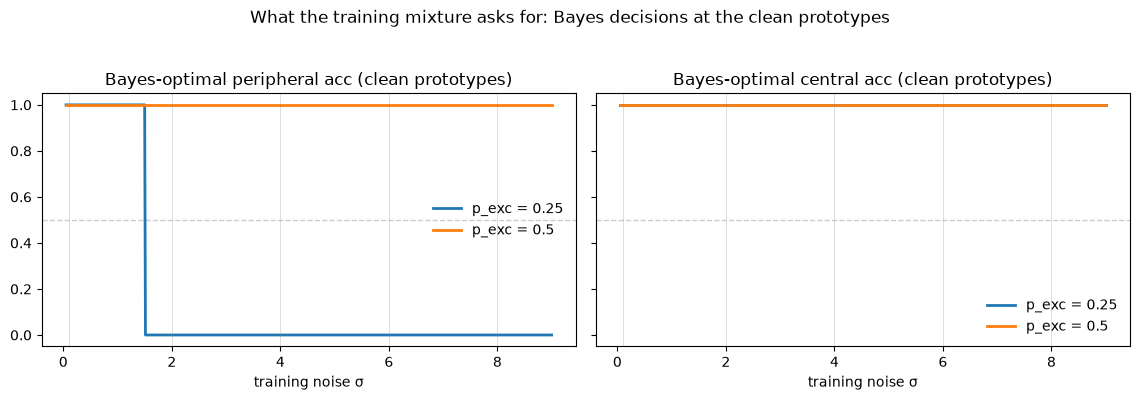

 sigma  p_exc  bayes_central  bayes_periph  bayes_all
   0.1   0.25            1.0           1.0       1.00
   0.1   0.50            1.0           1.0       1.00
   1.0   0.25            1.0           1.0       1.00
   1.0   0.50            1.0           1.0       1.00
   1.5   0.25            1.0           1.0       1.00
   1.5   0.50            1.0           1.0       1.00
   2.0   0.25            1.0           0.0       0.75
   2.0   0.50            1.0           1.0       1.00
   4.0   0.25            1.0           0.0       0.75
   4.0   0.50            1.0           1.0       1.00
   6.0   0.25            1.0           0.0       0.75
   6.0   0.50            1.0           1.0       1.00
   8.0   0.25            1.0           0.0       0.75
   8.0   0.50            1.0           1.0       1.00


In [8]:
# ── H1 ideal observer: the Bayes-optimal boundary itself depends on the exception mass ──
# Training data is a Gaussian mixture: 8 prototype means, isotropic σ²I noise, mixture
# weight p_exc/2 on each exception and (1 − p_exc)/6 on each central prototype. The
# population-optimal BCE predictor is the posterior log-odds, so its sign at a clean
# prototype is what an infinite-capacity, fully-converged learner tracking that mixture
# would answer there. Standard's stationary target is p_exc = 0.25; curriculum's
# ENDPOINT target is p_exc = 0.5. Wherever the two targets disagree on the exceptions,
# a curriculum "benefit" is available from pure distribution tracking (H1) — no better
# learning required.

def bayes_clean_prototype_acc(task, p_exc, sigma):
    X = np.concatenate([task.x_central, task.x_peripheral]).astype(np.float64)
    y = np.concatenate([task.y_central, task.y_peripheral])
    w = np.concatenate([np.full(6, (1.0 - p_exc) / 6), np.full(2, p_exc / 2)])
    d2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(-1)        # d2[i, j] = ‖x_i − μ_j‖²
    log_joint = -d2 / (2 * sigma ** 2) + np.log(w)[None, :]    # up to shared constants
    m = log_joint.max(axis=1, keepdims=True)
    E = np.exp(log_joint - m)
    with np.errstate(divide="ignore"):        # a class can underflow at tiny σ; ±inf odds is the right answer
        log_odds = np.log(E[:, y == 1].sum(1)) - np.log(E[:, y == 0].sum(1))
    correct = (log_odds > 0) == (y == 1)
    return correct[:6].mean(), correct[6:].mean()

task_bayes = make_gaussian_type5_task(noise_std=1.0)   # σ is passed explicitly below

sigmas_bayes = np.linspace(0.05, 9.0, 600)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for p_exc, color in [(0.25, "C0"), (0.5, "C1")]:
    accs = np.array([bayes_clean_prototype_acc(task_bayes, p_exc, s) for s in sigmas_bayes])
    axes[0].plot(sigmas_bayes, accs[:, 1], color=color, lw=2, label=f"p_exc = {p_exc}")
    axes[1].plot(sigmas_bayes, accs[:, 0], color=color, lw=2, label=f"p_exc = {p_exc}")
axes[0].set_title("Bayes-optimal peripheral acc (clean prototypes)")
axes[1].set_title("Bayes-optimal central acc (clean prototypes)")
for ax in axes:
    ax.set_xlabel("training noise σ")
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, color="gray", ls="--", lw=1, alpha=0.4)
    for s in [0.1, 2.0, 4.0, 6.0, 8.0]:
        ax.axvline(s, color="gray", lw=0.6, alpha=0.3)
    ax.legend(frameon=False)
plt.suptitle("What the training mixture asks for: Bayes decisions at the clean prototypes", y=1.04)
plt.tight_layout()
plt.show()

rows = []
for s in [0.1, 1.0, 1.5, 2.0, 4.0, 6.0, 8.0]:
    for p_exc in [0.25, 0.5]:
        c, p = bayes_clean_prototype_acc(task_bayes, p_exc, s)
        rows.append(dict(sigma=s, p_exc=p_exc, bayes_central=c, bayes_periph=p,
                         bayes_all=(6 * c + 2 * p) / 8))
print(pd.DataFrame(rows).round(3).to_string(index=False))

### Representation probes: main effects vs interactions

On the ±1 cube, any per-prototype vector (a unit's 8 clean activations, the labels) decomposes **exactly** in the orthogonal basis {1, s₀, s₁, s₂} ⊕ {s₀s₁, s₀s₂, s₁s₂, s₀s₁s₂}: main effects vs interactions (equivalently, degree ≤ 1 vs degree ≥ 2 Fourier). Three facts drive the metrics:

- The labels' exception content is **pure interaction**: no linear function of the inputs classifies all 8 prototypes (the best linear function is the rule, 6/8).
- A unit tuned to a single input (w ∝ e₀) is **exactly affine** across the corners — zero interaction content. The rule can be solved entirely by such units.
- Conjunction-like units (e.g. relu(s₀ + s₁ − 1)) carry interaction content — the resource the exceptions require.

Per checkpoint, computed on the clean prototypes: **nonlin_index** — interaction share of the representation's item-to-item variance; **residual_pr** — participation ratio of the interaction content (≤ 4 dimensions); **aligned_frac** — variance fraction along the *one* interaction direction the labels need; **refit accs** — whether a fresh ridge readout on the frozen features can solve the task (capacity, independent of the readout SGD actually learned).

In [9]:
# ── H3 probes: main-effect vs interaction decomposition of the hidden layer ──
# On the ±1 cube the 8 functions {1, s0, s1, s2} ∪ {s0s1, s0s2, s1s2, s0s1s2} form an
# orthogonal basis for "one value per prototype" vectors. A unit's tuning (its 8 clean
# activations) therefore splits EXACTLY into a main-effect part — reproducible by a
# linear function of the inputs — and an interaction part, which no linear function can
# mimic. The exception labels live entirely in the interaction span, so any exception
# capacity must show up there.

def clean_proto_matrices(task):
    X = np.concatenate([task.x_central, task.x_peripheral]).astype(np.float64)
    y = np.concatenate([task.y_central, task.y_peripheral]).astype(np.float64)
    return X, 2.0 * y - 1.0

def make_cube_bases(task):
    X, t = clean_proto_matrices(task)
    s0, s1, s2 = X.T
    B_lin = np.stack([np.ones(8), s0, s1, s2], 1) / np.sqrt(8.0)       # orthonormal cols
    B_int = np.stack([s0 * s1, s0 * s2, s1 * s2, s0 * s1 * s2], 1) / np.sqrt(8.0)
    t_int = B_int @ (B_int.T @ t)                # the labels' interaction component
    return dict(B_lin=B_lin, B_int=B_int, u_exc=t_int / np.linalg.norm(t_int), X=X, t=t)

def refit_readout_clean_from_H(H, bases, ridge=1e-4):
    """Freeze features, ridge-fit a fresh readout on the 8 clean prototypes.
    Measures whether the representation SUPPORTS the task, independent of the readout
    SGD happened to learn. Ridge is relative to feature scale."""
    t = bases["t"]
    Phi = np.concatenate([H, np.ones((8, 1))], 1)
    G = Phi.T @ Phi
    lam = ridge * np.trace(G) / len(G)
    v = np.linalg.solve(G + lam * np.eye(len(G)), Phi.T @ t)
    pred = Phi @ v
    ok = np.sign(pred) == t
    return dict(refit_central_acc=ok[:6].mean(), refit_periph_acc=ok[6:].mean())

@torch.no_grad()
def probe_representation(model, task, bases):
    """Four numbers per checkpoint:
      nonlin_index — interaction share of the representation's item-to-item variance
      residual_pr  — participation ratio of the interaction content (≤ 4 dims)
      aligned_frac — share of variance along the ONE interaction direction the labels need
      refit_*      — can an oracle readout of these frozen features solve the task?"""
    dev = next(model.parameters()).device
    H = model.hidden(torch.as_tensor(bases["X"], dtype=torch.float32, device=dev))
    H = H.double().cpu().numpy()                                   # (8, K)
    Hc = H - H.mean(0, keepdims=True)
    total_var = (Hc ** 2).sum()
    R = bases["B_int"] @ (bases["B_int"].T @ H)                    # interaction content
    int_var = (R ** 2).sum()
    lam = np.clip(np.linalg.eigvalsh(R @ R.T), 0.0, None)          # item-space spectrum
    out = dict(
        nonlin_index=float(int_var / max(total_var, 1e-15)),
        residual_pr=float(lam.sum() ** 2 / (lam ** 2).sum()) if lam.sum() > 1e-15 else 0.0,
        aligned_frac=float(((bases["u_exc"] @ H) ** 2).sum() / max(total_var, 1e-15)),
        repr_var=float(total_var),
    )
    out.update(refit_readout_clean_from_H(H, bases))
    return out

def refit_readout_distribution(model, task, p_exc, n_samples=8192, seed=0,
                               steps=400, lr=0.1):
    """Freeze W, b; retrain ONLY the readout (v, c) by logistic regression on a fresh
    noisy sample with exception mass p_exc; evaluate on the clean prototypes.
    Answers: what would this representation score if its readout were optimal for that
    mixture? If refitting closes the standard-vs-curriculum gap, the deficit was readout
    placement (H1/H2); if not, it is representational (H3)."""
    dev = next(model.parameters()).device
    p = np.full(n_samples, p_exc, dtype=np.float32)
    X, y, _, _ = make_trial_sequence_gaussian(task, p, seed=seed, device=dev)
    with torch.no_grad():
        Phi = model.hidden(X)
    v = torch.zeros(Phi.shape[1], requires_grad=True, device=dev)
    c = torch.zeros((), requires_grad=True, device=dev)
    opt = torch.optim.Adam([v, c], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(Phi @ v + c, y)
        loss.backward()
        opt.step()
    with torch.no_grad():
        bases = make_cube_bases(task)
        H8 = model.hidden(torch.as_tensor(bases["X"], dtype=torch.float32, device=dev))
        logits = (H8 @ v + c).cpu().numpy()
        ok = np.sign(logits) == bases["t"]
    return dict(central_acc=ok[:6].mean(), periph_acc=ok[6:].mean())

In [10]:
# ── Probe sanity: hand-built tunings behave exactly as the math says ──
task_H0 = make_gaussian_type5_task(noise_std=2.0)
bases_H0 = make_cube_bases(task_H0)
X8, t8 = bases_H0["X"], bases_H0["t"]

# The two spans really are orthonormal complements of item space
B_full = np.concatenate([bases_H0["B_lin"], bases_H0["B_int"]], 1)
assert np.allclose(B_full.T @ B_full, np.eye(8), atol=1e-12)

def interaction_share(h):
    lin = bases_H0["B_lin"] @ (bases_H0["B_lin"].T @ h)
    inter = bases_H0["B_int"] @ (bases_H0["B_int"].T @ h)
    assert np.allclose(lin + inter, h, atol=1e-9)          # exact decomposition
    hc = h - h.mean()
    return (inter ** 2).sum() / (hc ** 2).sum()

h_rule = np.maximum(0.0, 2.0 * X8[:, 0])                   # unit tuned to s0 alone
h_and = np.maximum(0.0, X8[:, 0] + X8[:, 1] - 1.0)         # fires only when s0 = s1 = +1
print(f"interaction share of tuning variance — rule unit: {interaction_share(h_rule):.3f}   "
      f"AND unit: {interaction_share(h_and):.3f}   labels: {interaction_share(t8):.3f}")

# The labels need interactions: a readout on the raw inputs caps at 6/8
print("readout on raw inputs (linear ceiling):",
      {k: round(float(v), 3) for k, v in refit_readout_clean_from_H(X8, bases_H0).items()})

# Random-init nets calibrate the probes: random ReLU tunings carry some interaction
# variance by chance, so the trained trajectories must be read against this floor.
# NOTE the random-init refit accs are already 1.0: with K = 32 the 8 clean points are
# interpolable from init (kernel-style), so refit ACCURACY saturates and the
# variance-based probes + distribution refits below carry the discrimination.
rand_probes = []
for sid in range(10):
    torch.manual_seed(7000 + sid)
    net0 = GaussianReLUNet(n_hidden=32, input_dim=task_H0.input_dim, init_std=0.05).to(device)
    rand_probes.append(probe_representation(net0, task_H0, bases_H0))
rand_probes = pd.DataFrame(rand_probes).mean()
RAND_NONLIN_H = float(rand_probes["nonlin_index"])    # chance floor, interaction share
RAND_ALIGNED_H = float(rand_probes["aligned_frac"])   # chance floor, aligned fraction
print("random init (mean over 10):", rand_probes.round(3).to_dict())

interaction share of tuning variance — rule unit: 0.000   AND unit: 0.333   labels: 0.750
readout on raw inputs (linear ceiling): {'refit_central_acc': 1.0, 'refit_periph_acc': 0.0}
random init (mean over 10): {'nonlin_index': 0.2, 'residual_pr': 2.657, 'aligned_frac': 0.04, 'repr_var': 0.201, 'refit_central_acc': 1.0, 'refit_periph_acc': 1.0}


### Schedule controls

Six schedules at σ = 2.0, K = 32, T = 15000 (the regime where the curriculum benefit is large and not zero-sum). All matched on **total** exception exposure (mean p = 0.25) except `const_0.5`, which matches curriculum's **endpoint** instead.

| condition | schedule | what it unconfounds |
|---|---|---|
| `standard` | constant 0.25 | baseline |
| `curriculum` | ramp 0 → 0.5 | the effect to explain |
| `late_step` | 0 until T/2, then 0.5 | endpoint + exposure matched, no ramp → is gradualness needed? |
| `anti_curriculum` | ramp 0.5 → 0 | exposure early, endpoint ≈ 0 → timing sanity control |
| `ramp_then_drop` | ramp 0 → 0.625 over 0.8T, then 0 | curriculum-shaped but rule-only tail → does the benefit survive without recency? (H2) |
| `const_0.5` | constant 0.5 | endpoint reference, 2× exposure (H1 upper bound) |

Every run records behaviour (clean-prototype accuracies) **and** the representation probes every 100 steps; final models are kept for the refit decomposition.

In [11]:
# ── Schedule controls × representation probes: one tracked experiment ──
# Six schedules at σ = 2.0, K = 32, T = 15000 — the regime where the curriculum benefit
# is large and not zero-sum. All matched on TOTAL exception exposure (mean p = 0.25)
# except const_0.5, which matches curriculum's ENDPOINT instead:
#   standard         constant 0.25                       baseline
#   curriculum       ramp 0 → 0.5                        the effect to explain
#   late_step        0 until T/2, then 0.5               matched endpoint + exposure, no ramp → is gradualness needed?
#   anti_curriculum  ramp 0.5 → 0                        exposure early, endpoint 0 → timing sanity control
#   ramp_then_drop   ramp 0 → 0.625 over 0.8T, then 0    curriculum-shaped, rule-only tail → survives without recency? (H2)
#   const_0.5        constant 0.5                        endpoint reference, 2× exposure (H1 upper bound)

def train_one_run_probed(task, p_exception, seed=0, seed_id=None, condition="condition",
                         n_hidden=32, init_std=0.05, lr=0.01, eval_every=100,
                         loss_type="bce"):
    """Same minimal single-trial SGD loop as train_one_run_gaussian, plus
    representation probes at every eval checkpoint."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = GaussianReLUNet(n_hidden=n_hidden, input_dim=task.input_dim,
                            init_std=init_std).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    X_seq, y_seq, is_exception, _ = make_trial_sequence_gaussian(
        task, p_exception, seed=seed, device=device)
    bases = make_cube_bases(task)
    rows = []

    def record(step):
        metrics = evaluate_model_clean(model, task, loss_type=loss_type)
        metrics.update(probe_representation(model, task, bases))
        metrics.update(condition=condition,
                       seed=seed_id if seed_id is not None else seed,
                       step=step,
                       p_exception=float(p_exception[min(step, len(p_exception) - 1)]))
        rows.append(metrics)
        model.train()

    n_steps = len(p_exception)
    record(0)
    for i in range(n_steps):
        optimizer.zero_grad()
        logit = model(X_seq[i:i + 1]).view(-1)
        loss = compute_loss_from_logits(logit, y_seq[i:i + 1], loss_type)
        loss.backward()
        optimizer.step()
        if ((i + 1) % eval_every == 0) or (i + 1 == n_steps):
            record(i + 1)
    return model, pd.DataFrame(rows)

T_H, SIGMA_H, K_H, N_SEEDS_H = 15000, 2.0, 32, 10

def build_schedules_H(T):
    n80 = int(round(0.8 * T))
    ramp_drop = np.zeros(T, dtype=np.float32)
    ramp_drop[:n80] = np.linspace(0.0, 0.625, n80)
    late = np.zeros(T, dtype=np.float32)
    late[T // 2:] = 0.5
    return {
        "standard":        np.full(T, 0.25, dtype=np.float32),
        "curriculum":      np.linspace(0.0, 0.5, T).astype(np.float32),
        "late_step":       late,
        "anti_curriculum": np.linspace(0.5, 0.0, T).astype(np.float32),
        "ramp_then_drop":  ramp_drop,
        "const_0.5":       np.full(T, 0.5, dtype=np.float32),
    }

SCHEDULES_H = build_schedules_H(T_H)
print("mean p(exception):", {k: round(float(v.mean()), 4) for k, v in SCHEDULES_H.items()})

task_H = make_gaussian_type5_task(noise_std=SIGMA_H)
models_H, hist_H_list = {}, []
for cond, sched in SCHEDULES_H.items():
    for sid in range(N_SEEDS_H):
        model, hist = train_one_run_probed(
            task_H, sched, seed=123 + sid, seed_id=sid, condition=cond,
            n_hidden=K_H, init_std=0.05, lr=0.01, eval_every=100)
        models_H[(cond, sid)] = model
        hist_H_list.append(hist)
    print(f"{cond} done")
hist_H = pd.concat(hist_H_list, ignore_index=True)

mean p(exception): {'standard': 0.25, 'curriculum': 0.25, 'late_step': 0.25, 'anti_curriculum': 0.25, 'ramp_then_drop': 0.25, 'const_0.5': 0.5}


standard done


curriculum done


late_step done


anti_curriculum done


ramp_then_drop done


const_0.5 done


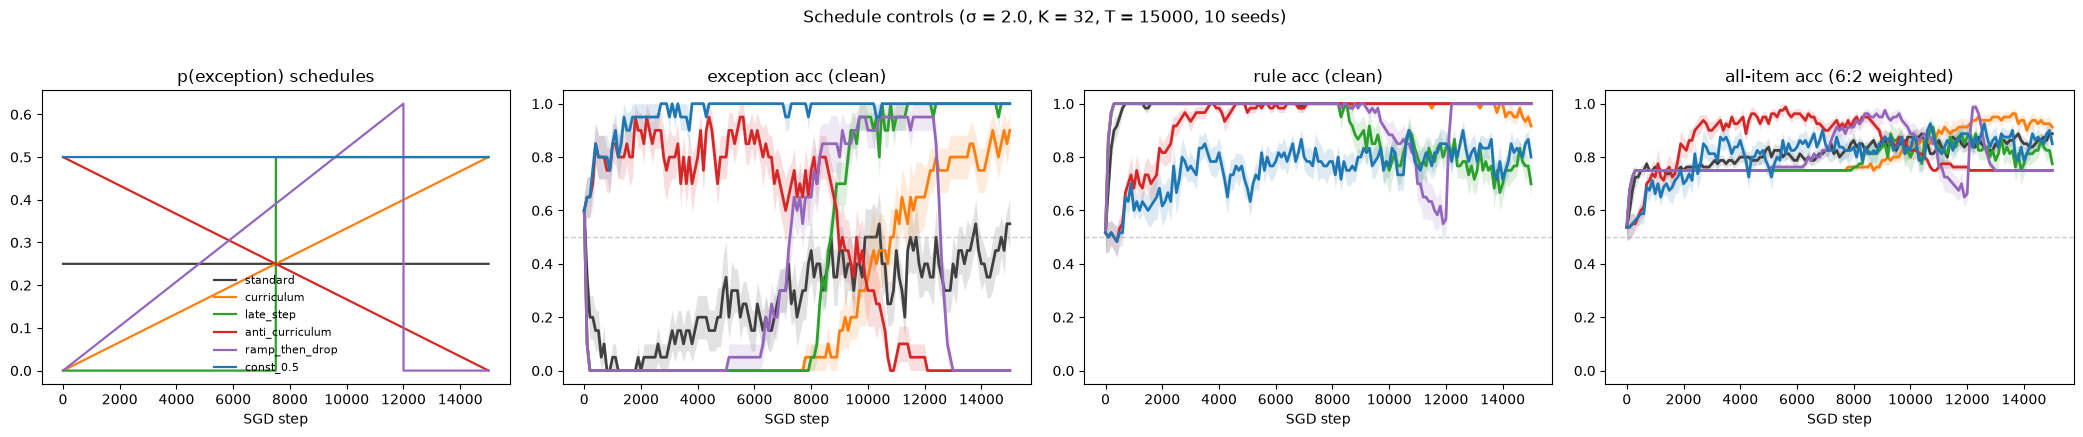

Final accuracies by condition:
                peripheral_acc        central_acc        all_acc_w       
                          mean    sem        mean    sem      mean    sem
condition                                                                
standard                  0.55  0.090       1.000  0.000     0.888  0.022
curriculum                0.90  0.067       0.917  0.028     0.912  0.019
late_step                 1.00  0.000       0.700  0.054     0.775  0.041
anti_curriculum           0.00  0.000       1.000  0.000     0.750  0.000
ramp_then_drop            0.00  0.000       1.000  0.000     0.750  0.000
const_0.5                 1.00  0.000       0.800  0.033     0.850  0.025


In [12]:
# ── Endpoint + trajectory comparison across the schedule controls ──
COND_COLORS = {
    "standard": "0.25", "curriculum": "C1", "late_step": "C2",
    "anti_curriculum": "C3", "ramp_then_drop": "C4", "const_0.5": "C0",
}
hist_H["all_acc_w"] = (6 * hist_H["central_acc"] + 2 * hist_H["peripheral_acc"]) / 8

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
ax = axes[0]
for cond, sched in SCHEDULES_H.items():
    ax.plot(sched, color=COND_COLORS[cond], lw=1.6, label=cond)
ax.set_title("p(exception) schedules")
ax.set_xlabel("SGD step")
ax.legend(frameon=False, fontsize=8)

for ax, metric, title in [(axes[1], "peripheral_acc", "exception acc (clean)"),
                          (axes[2], "central_acc", "rule acc (clean)"),
                          (axes[3], "all_acc_w", "all-item acc (6:2 weighted)")]:
    for cond in SCHEDULES_H:
        d = hist_H[hist_H["condition"] == cond]
        g = d.groupby("step")[metric]
        m, s = g.mean(), g.sem()
        ax.plot(m.index, m.values, color=COND_COLORS[cond], lw=2, label=cond)
        ax.fill_between(m.index, m - s, m + s, color=COND_COLORS[cond], alpha=0.15, lw=0)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
    ax.set_xlabel("SGD step")
    ax.axhline(0.5, color="gray", ls="--", lw=1, alpha=0.4)
plt.suptitle(f"Schedule controls (σ = {SIGMA_H}, K = {K_H}, T = {T_H}, {N_SEEDS_H} seeds)", y=1.03)
plt.tight_layout()
plt.show()

final_H = hist_H[hist_H["step"] == T_H]
print("Final accuracies by condition:")
print(final_H.groupby("condition")[["peripheral_acc", "central_acc", "all_acc_w"]]
      .agg(["mean", "sem"]).round(3).loc[list(SCHEDULES_H)].to_string())

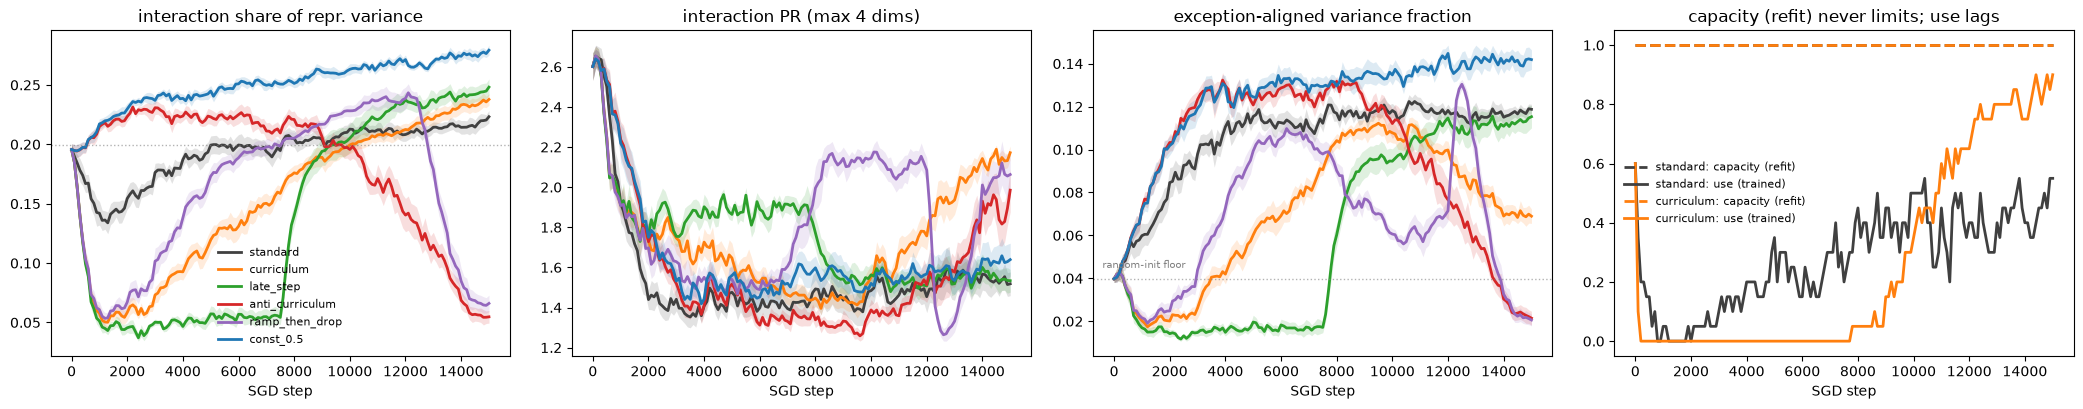

In [13]:
# ── H3: does curriculum drive expansion into the interaction (nonlinear) subspace? ──
# Panel 4 overlays capacity (oracle refit on frozen features, dashed) with use
# (the readout SGD actually learned, solid). If the dashed lines sit at 1.0 throughout
# — as the random-init calibration predicts at K = 32 — representational CAPACITY is
# never the bottleneck, and the action is in which variance the online readout can
# stably exploit (panels 1–3).
PROBE_CONDS = ["standard", "curriculum", "late_step", "anti_curriculum",
               "ramp_then_drop", "const_0.5"]

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
panels = [("nonlin_index", "interaction share of repr. variance"),
          ("residual_pr", "interaction PR (max 4 dims)"),
          ("aligned_frac", "exception-aligned variance fraction")]
for ax, (metric, title) in zip(axes[:3], panels):
    for cond in PROBE_CONDS:
        d = hist_H[hist_H["condition"] == cond]
        g = d.groupby("step")[metric]
        m, s = g.mean(), g.sem()
        ax.plot(m.index, m.values, color=COND_COLORS[cond], lw=2, label=cond)
        ax.fill_between(m.index, m - s, m + s, color=COND_COLORS[cond], alpha=0.15, lw=0)
    ax.set_title(title)
    ax.set_xlabel("SGD step")
axes[0].legend(frameon=False, fontsize=8)
axes[0].axhline(RAND_NONLIN_H, color="gray", ls=":", lw=1, alpha=0.6)
axes[2].axhline(RAND_ALIGNED_H, color="gray", ls=":", lw=1, alpha=0.6)
axes[2].text(0.02, RAND_ALIGNED_H + 0.005, "random-init floor", fontsize=7, color="gray",
             transform=axes[2].get_yaxis_transform())

ax = axes[3]
for cond in ["standard", "curriculum"]:
    d = hist_H[hist_H["condition"] == cond]
    for met, ls, tag in [("refit_periph_acc", "--", "capacity (refit)"),
                         ("peripheral_acc", "-", "use (trained)")]:
        g = d.groupby("step")[met].mean()
        ax.plot(g.index, g.values, ls, color=COND_COLORS[cond], lw=2,
                label=f"{cond}: {tag}")
ax.set_ylim(-0.05, 1.05)
ax.set_title("capacity (refit) never limits; use lags")
ax.set_xlabel("SGD step")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

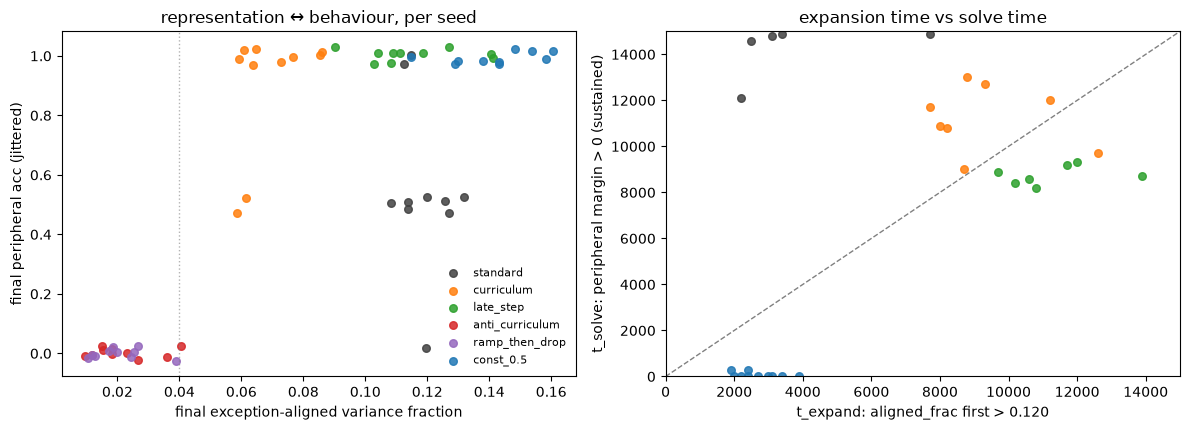

                  t_expand  t_solve  final_aligned  solved
condition                                                 
standard          5150.000  14260.0          0.119     0.5
curriculum        9312.500  11170.0          0.069     1.0
late_step        11271.429   8850.0          0.115     1.0
anti_curriculum   2600.000      NaN          0.021     0.0
ramp_then_drop    8370.000      NaN          0.021     0.0
const_0.5         2700.000     60.0          0.142     1.0

corr(t_expand, t_solve) over solved runs: 0.490  (n = 30)


In [14]:
# ── Per-seed coupling between representational expansion and exception learning ──
# If H3 is right, solving the exceptions should be time-locked, seed by seed, to the
# representation concentrating variance on the exception direction — and seeds that
# never expand should never solve.
THETA_EXPAND = 3.0 * RAND_ALIGNED_H   # aligned_frac well above the random-init floor

rows = []
for (cond, sid), d in hist_H.groupby(["condition", "seed"]):
    d = d.sort_values("step")
    af = d["aligned_frac"].values
    steps = d["step"].values
    above = steps[af > THETA_EXPAND]
    m = d["peripheral_margin"].values
    solved = m[-1] > 0
    below = steps[m <= 0]
    rows.append(dict(condition=cond, seed=sid,
                     t_expand=above[0] if len(above) else np.nan,
                     t_solve=(below[-1] if len(below) else 0) if solved else np.nan,
                     final_aligned=af[-1],
                     final_periph=d["peripheral_acc"].iloc[-1]))
coupling_H = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
rng_j = np.random.default_rng(0)
for cond in SCHEDULES_H:
    d = coupling_H[coupling_H["condition"] == cond]
    jitter = (rng_j.random(len(d)) - 0.5) * 0.06
    ax.scatter(d["final_aligned"], d["final_periph"] + jitter, s=30,
               color=COND_COLORS[cond], label=cond, alpha=0.85)
ax.set_xlabel("final exception-aligned variance fraction")
ax.set_ylabel("final peripheral acc (jittered)")
ax.axvline(RAND_ALIGNED_H, color="gray", ls=":", lw=1, alpha=0.6)
ax.legend(frameon=False, fontsize=8)
ax.set_title("representation ↔ behaviour, per seed")

ax = axes[1]
d_ok = coupling_H.dropna(subset=["t_expand", "t_solve"])
for cond in SCHEDULES_H:
    dc = d_ok[d_ok["condition"] == cond]
    ax.scatter(dc["t_expand"], dc["t_solve"], s=30, color=COND_COLORS[cond],
               alpha=0.85, label=cond)
ax.plot([0, T_H], [0, T_H], color="gray", lw=1, ls="--")
ax.set_xlim(0, T_H); ax.set_ylim(0, T_H)
ax.set_xlabel(f"t_expand: aligned_frac first > {THETA_EXPAND:.3f}")
ax.set_ylabel("t_solve: peripheral margin > 0 (sustained)")
ax.set_title("expansion time vs solve time")
plt.tight_layout()
plt.show()

n_solved = coupling_H.assign(solved=coupling_H["t_solve"].notna())
print(n_solved.groupby("condition")[["t_expand", "t_solve", "final_aligned", "solved"]]
      .mean().round(3).loc[list(SCHEDULES_H)].to_string())
sub = coupling_H.dropna(subset=["t_expand", "t_solve"])
if len(sub) > 2:
    print(f"\ncorr(t_expand, t_solve) over solved runs: "
          f"{np.corrcoef(sub['t_expand'], sub['t_solve'])[0, 1]:.3f}  (n = {len(sub)})")

Peripheral / central acc on clean prototypes, by readout regime (means):
                 trained_periph  trained_central  clean_periph  p25_periph  p25_central  p50_periph  p50_central
condition                                                                                                       
standard                   0.55            1.000           1.0        0.65          1.0         1.0        0.933
curriculum                 0.90            0.917           1.0        0.40          1.0         1.0        0.817
late_step                  1.00            0.700           1.0        0.70          1.0         1.0        0.867
anti_curriculum            0.00            1.000           1.0        0.50          1.0         1.0        0.933
ramp_then_drop             0.00            1.000           1.0        0.55          1.0         1.0        0.883
const_0.5                  1.00            0.800           1.0        0.70          1.0         1.0        0.933
random_init            

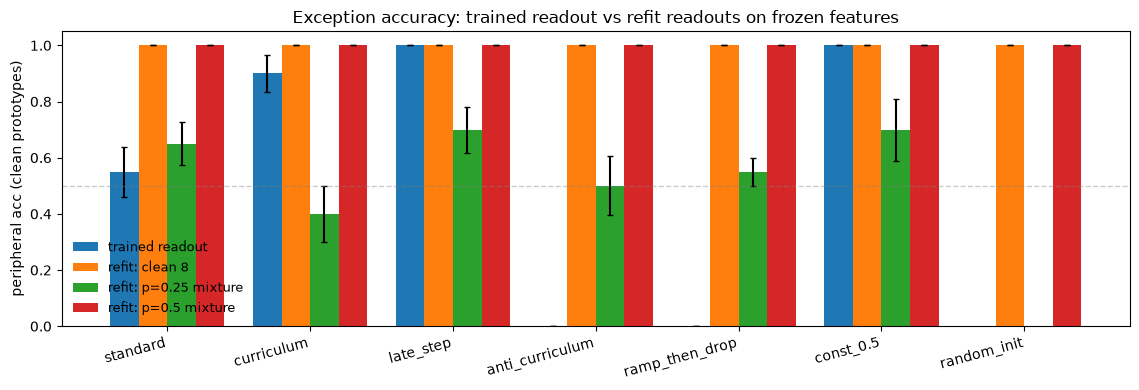

In [15]:
# ── Refit decomposition: how much of the endpoint gap is readout vs representation? ──
# For each trained net, freeze W, b and ask what a FRESH readout could do:
#   clean   — ridge on the 8 clean prototypes (pure capacity question)
#   p=0.25 / p=0.5 — logistic readout retrained on the noisy mixture with that exception
#     mass (what standard's / curriculum's endpoint distribution asks of a readout)
# Random-init nets calibrate both metrics (random ReLU features have some capacity).
# Reading: if standard's p=0.5 refit matches curriculum, the gap was readout placement
# (H1/H2 — the features were fine); if it stays low, the gap is representational (H3).

refit_rows = []
bases_H = make_cube_bases(task_H)
for (cond, sid), model in models_H.items():
    pr = probe_representation(model, task_H, bases_H)
    r25 = refit_readout_distribution(model, task_H, p_exc=0.25, seed=1000 + sid)
    r50 = refit_readout_distribution(model, task_H, p_exc=0.5, seed=2000 + sid)
    fin = hist_H[(hist_H["condition"] == cond) & (hist_H["seed"] == sid)
                 & (hist_H["step"] == T_H)].iloc[0]
    refit_rows.append(dict(
        condition=cond, seed=sid,
        trained_periph=fin["peripheral_acc"], trained_central=fin["central_acc"],
        clean_periph=pr["refit_periph_acc"],
        p25_periph=r25["periph_acc"], p25_central=r25["central_acc"],
        p50_periph=r50["periph_acc"], p50_central=r50["central_acc"]))

for sid in range(N_SEEDS_H):
    torch.manual_seed(9000 + sid)
    net0 = GaussianReLUNet(n_hidden=K_H, input_dim=task_H.input_dim, init_std=0.05).to(device)
    pr = probe_representation(net0, task_H, bases_H)
    r50 = refit_readout_distribution(net0, task_H, p_exc=0.5, seed=3000 + sid)
    refit_rows.append(dict(
        condition="random_init", seed=sid,
        trained_periph=np.nan, trained_central=np.nan,
        clean_periph=pr["refit_periph_acc"],
        p25_periph=np.nan, p25_central=np.nan,
        p50_periph=r50["periph_acc"], p50_central=r50["central_acc"]))

refit_H = pd.DataFrame(refit_rows)
order_H = list(SCHEDULES_H) + ["random_init"]
print("Peripheral / central acc on clean prototypes, by readout regime (means):")
print(refit_H.groupby("condition").mean(numeric_only=True).drop(columns="seed")
      .loc[order_H].round(3).to_string())

fig, ax = plt.subplots(figsize=(11.5, 4))
metrics_bar = ["trained_periph", "clean_periph", "p25_periph", "p50_periph"]
labels_bar = ["trained readout", "refit: clean 8", "refit: p=0.25 mixture", "refit: p=0.5 mixture"]
xs = np.arange(len(order_H))
width = 0.2
for k, (met, lab) in enumerate(zip(metrics_bar, labels_bar)):
    vals = [refit_H[refit_H["condition"] == c][met].mean() for c in order_H]
    sems = [refit_H[refit_H["condition"] == c][met].sem() for c in order_H]
    ax.bar(xs + (k - 1.5) * width, vals, width, yerr=sems, capsize=2, label=lab)
ax.set_xticks(xs)
ax.set_xticklabels(order_H, rotation=15, ha="right")
ax.set_ylabel("peripheral acc (clean prototypes)")
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color="gray", ls="--", lw=1, alpha=0.4)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Exception accuracy: trained readout vs refit readouts on frozen features")
plt.tight_layout()
plt.show()

### Findings

**H1 (distribution tracking) is the dominant driver of the raw peripheral gap.** The ideal observer shows the Bayes-optimal decision at the clean exception prototypes flips to the *rule* label at **σ ≈ 1.51** under the p = 0.25 mixture, while the p = 0.5 mixture keeps the exceptions correct at every σ tested (checked up to σ = 30). So at σ ≥ 2 standard's stationary target *does not ask for the exceptions at all*, while curriculum's endpoint target does. Endpoint distribution alone organises the final peripheral accuracies: endpoint-0.5 conditions reach 0.90–1.0 (`curriculum` 0.90, `late_step` 1.0, `const_0.5` 1.0), endpoint-0 conditions reach 0.0 (`anti_curriculum`, `ramp_then_drop`), and `standard` sits at 0.55 — per-seed mostly *one* of the two exceptions (7/10 seeds at 0.5), consistent with hovering at a marginal target. This also explains Sweep A's high-σ pattern: the peripheral gain / central loss there is the boundary shift the p = 0.5 endpoint requests, not better learning. Note σ = 1.5 (Sweeps B–C) sits just *below* the flip — there the p = 0.25 target still includes the exceptions, which is why standard eventually catches up with enough T or K.

**H2 (forgetting) is real, fast, and representational.** `ramp_then_drop` reaches 0.95 peripheral by step ~9700, then loses *everything* within ~900 rule-only steps of the tail (mean peripheral < 0.1 by step 12900). The probes show this is not mere readout drift: exception-aligned variance collapses from 0.071 to 0.021 — **below the random-init floor of 0.04**. Rule-dominated training actively *linearises* the hidden layer, squeezing interaction variance out. The same signature appears in curriculum's own opening: during its pure-rule phase, aligned_frac dips to 0.017 (step ~1200) before exception pressure re-expands it. The representation is not a ratchet; it is an equilibrium tracking the recent trial stream — which is simplicity bias operating continuously in representation space.

**H3-as-readiness is rejected in this regime, three ways.** (i) `anti_curriculum` learns the exceptions essentially perfectly from step ~1800 (peak peripheral 0.95) — an immature, small-init network encodes them fine; the problem is keeping them. (ii) Expansion time tracks *exposure*, not network maturity: t_expand ordering (`anti` ≈ `const_0.5` ≈ 2600–2700 < `standard` 5150 < `curriculum` 9300 < `late_step` 11300) is exactly the order in which exception pressure arrives. (iii) Capacity is never the bottleneck: an oracle readout on frozen features scores 8/8 even at *random init* (K = 32 interpolates the 8 clean prototypes), and the p = 0.5-mixture refit also solves the exceptions on every condition's features, including random ones. Expansion and solving are nevertheless tightly coupled per seed (corr(t_expand, t_solve) ≈ 0.49, and no run solves while aligned_frac sits below the random floor) — the representational event is real; it just isn't gated by readiness.

**What the gradual ramp actually buys: installing the exceptions without destroying the rule.** All three endpoint-0.5 conditions install the exceptions, but at sharply different central cost: `curriculum` keeps central at 0.917 vs `const_0.5` 0.80 and `late_step` 0.70; weighted all-item accuracy is `curriculum` 0.912 > `standard` 0.888 > `const_0.5` 0.850 > `late_step` 0.775. Notably `late_step` is *worse* than `const_0.5` on the rule despite a rule-only first half — so early consolidation per se does not protect the rule; **abrupt shifts in the mixture are what damage it**. Gradualness is unnecessary for the exceptions (a hard switch installs them fine) but is precisely what preserves the rule while they are installed.

**Reframed conclusion.** In this noise regime, "curriculum helps" decomposes into: (a) an endpoint-distribution effect (H1) that any schedule ending at p = 0.5 gets — this is most of the raw peripheral gap; (b) a fast erasure constraint (H2) that dooms any schedule *not* ending with exception pressure; and (c) a genuinely curriculum-specific effect that is the *opposite* of the readiness story: the ramp doesn't scaffold the exceptions, it protects the rule from the distribution shift that installs them.

**Caveats / next steps.** Conclusions are for σ = 2, K = 32, T = 15k. Below the Bayes flip (σ < 1.5) both mixtures target the exceptions, so any curriculum benefit surviving there (cf. Sweep B small-T effects) would be genuinely dynamical rather than H1 — worth an explicit sweep. A block-insertion design (one exception block at varying position, probed immediately after the block and at the end) would time-resolve encoding vs erasure per exposure. Sweep C (init rank) remains the direct bridge to the Claim-3 PR-interaction prediction.

### Follow-up: does a maintenance dose prevent forgetting? (hysteresis control)

Ramp 0 → 0.5, then drop to the **base rate 0.25** at the end (not to 0). This matches `standard` on total exposure (the ramp itself averages 0.25) *and* on endpoint distribution — the strongest recency control: the only difference from `standard` is history. `standard` arrives at p = 0.25 never having built the exceptions; this schedule arrives with them fully installed.

- **Consolidation reading:** once installed, the exceptions survive on a 0.25 maintenance dose → the p = 0.25 stream is bistable, and history matters (a real dynamical effect beyond distribution tracking).
- **Tracking reading:** the p = 0.25 stream defines a single stationary state (σ = 2 is past the Bayes flip, so that state holds at most one exception), and the system relaxes to it regardless of history.

Two tail lengths (20% and 50% of T) separate *stable maintenance* from *slow decay*.

mean p: {'ramp_then_settle_20': 0.25, 'ramp_then_settle_50': 0.25}


ramp_then_settle_20 done


ramp_then_settle_50 done


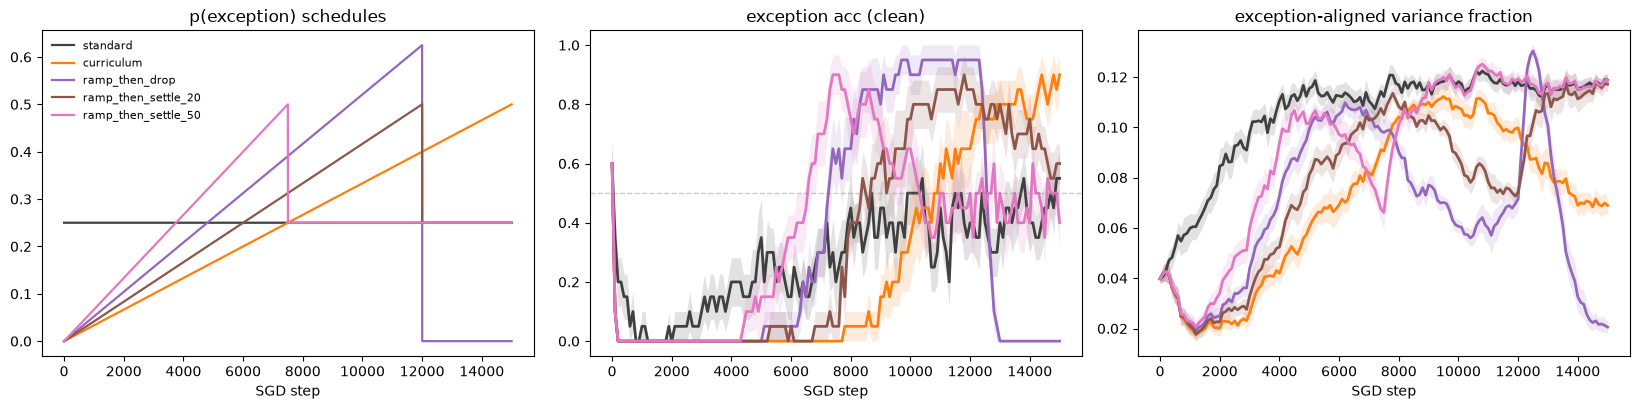

                    peripheral_acc        central_acc        aligned_frac       
                              mean    sem        mean    sem         mean    sem
condition                                                                       
standard                      0.55  0.090       1.000  0.000        0.119  0.002
curriculum                    0.90  0.067       0.917  0.028        0.069  0.003
ramp_then_drop                0.00  0.000       1.000  0.000        0.021  0.003
ramp_then_settle_20           0.60  0.067       1.000  0.000        0.117  0.003
ramp_then_settle_50           0.40  0.100       1.000  0.000        0.119  0.002

ramp_then_settle_20: per-seed final periph [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 1.0, 1.0]
ramp_then_settle_50: per-seed final periph [0.0, 0.0, 0.0, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 1.0]
standard: per-seed final periph [0.0, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 1.0, 1.0]


In [16]:
# ── Hysteresis control: ramp 0 → 0.5, then settle at the base rate 0.25 ──
def settle_schedule(T, ramp_frac):
    n_ramp = int(round(ramp_frac * T))
    p = np.full(T, 0.25, dtype=np.float32)
    p[:n_ramp] = np.linspace(0.0, 0.5, n_ramp)
    return p

SETTLE_SCHEDS = {
    "ramp_then_settle_20": settle_schedule(T_H, 0.8),   # 12000 ramp + 3000 @ 0.25
    "ramp_then_settle_50": settle_schedule(T_H, 0.5),   # 7500 ramp + 7500 @ 0.25
}
print("mean p:", {k: round(float(v.mean()), 4) for k, v in SETTLE_SCHEDS.items()})

hist_S_list = []
for cond, sched in SETTLE_SCHEDS.items():
    for sid in range(N_SEEDS_H):
        _, hist = train_one_run_probed(
            task_H, sched, seed=123 + sid, seed_id=sid, condition=cond,
            n_hidden=K_H, init_std=0.05, lr=0.01, eval_every=100)
        hist_S_list.append(hist)
    print(cond, "done")
hist_S = pd.concat(hist_S_list, ignore_index=True)
both_S = pd.concat([hist_H, hist_S], ignore_index=True)

SETTLE_COLORS = {**COND_COLORS, "ramp_then_settle_20": "C5", "ramp_then_settle_50": "C6"}
show_S = ["standard", "curriculum", "ramp_then_drop",
          "ramp_then_settle_20", "ramp_then_settle_50"]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2))
ax = axes[0]
for cond in show_S:
    sched = SETTLE_SCHEDS.get(cond, SCHEDULES_H.get(cond))
    ax.plot(sched, color=SETTLE_COLORS[cond], lw=1.6, label=cond)
ax.set_title("p(exception) schedules")
ax.set_xlabel("SGD step")
ax.legend(frameon=False, fontsize=8)

for ax, metric, title in [(axes[1], "peripheral_acc", "exception acc (clean)"),
                          (axes[2], "aligned_frac", "exception-aligned variance fraction")]:
    for cond in show_S:
        d = both_S[both_S["condition"] == cond]
        g = d.groupby("step")[metric]
        m, s = g.mean(), g.sem()
        ax.plot(m.index, m.values, color=SETTLE_COLORS[cond], lw=2, label=cond)
        ax.fill_between(m.index, m - s, m + s, color=SETTLE_COLORS[cond], alpha=0.15, lw=0)
    ax.set_title(title)
    ax.set_xlabel("SGD step")
axes[1].set_ylim(-0.05, 1.05)
axes[1].axhline(0.5, color="gray", ls="--", lw=1, alpha=0.4)
plt.tight_layout()
plt.show()

fin_S = both_S[(both_S["step"] == T_H) & (both_S["condition"].isin(show_S))]
print(fin_S.groupby("condition")[["peripheral_acc", "central_acc", "aligned_frac"]]
      .agg(["mean", "sem"]).round(3).loc[show_S].to_string())
print()
for cond in ["ramp_then_settle_20", "ramp_then_settle_50", "standard"]:
    d = fin_S[fin_S["condition"] == cond]
    print(f"{cond}: per-seed final periph "
          f"{sorted(d['peripheral_acc'].round(2).tolist())}")

**Result: no hysteresis — the tracking reading wins.** Both settle variants relax to `standard`'s stationary state, from above instead of from below:

- `ramp_then_settle_20` decays from 0.85 peripheral at the drop to 0.60 at the end (per-seed [0.5 ×8, 1.0 ×2] vs standard's [0.0, 0.5 ×7, 1.0 ×2]); the longer-tail `ramp_then_settle_50` decays further, 0.90 → 0.40 — so the tail is *slow relaxation*, not maintenance. Extrapolated, both land on the one-exception-per-seed state that standard reaches from below.
- The representation converges too: final aligned_frac ≈ 0.117–0.119 for both settle variants **and** standard — same equilibrium, regardless of whether the exceptions were ever installed.
- Decay speed scales with the erosion pressure: at p = 0 (`ramp_then_drop`) erasure completes in ~900 steps; at p = 0.25 it takes thousands and stops at one exception rather than zero — exactly where the p = 0.25 mixture's optimum sits at σ = 2 (past the Bayes flip).

So a base-rate maintenance dose cannot preserve what it could not create: at σ = 2 the p = 0.25 stream defines a single history-independent equilibrium, and online SGD forgets its way to it. This sharpens the H1/H2 findings above — "recency" is not about the last few trials, it is that the *final training distribution's stationary state* is what you keep. A useful corollary for schedule design: any benefit of curriculum must be cashed out **at the endpoint distribution you intend to deploy under**; there is no banking of exception knowledge at these settings. (Whether bistability appears below the Bayes flip, at larger K, or with smaller lr — where SGD noise is weaker relative to the attractor — is the natural follow-up.)

### Follow-up 2: does the ramp durably protect the rule, or just delay erosion?

`const_0.5` never learns the rule well (central plateaus ≈ 0.8), and `late_step` learns it perfectly then loses it (→ 0.70) — so "the rule is maintained once learned" is not what separates curriculum (0.917) from the others. Two remaining candidates:

- **Robust-rule reading:** gradual arrival of exception pressure builds a rule representation that withstands p = 0.5.
- **Delayed-clock reading:** rule erosion toward the p = 0.5 equilibrium (central ≈ 0.7–0.8) runs at a fixed rate once p is high; curriculum looks good only because its ramp reaches 0.5 at the final step, so evaluation happens before erosion catches up.

Test: extend the ramp with a **hold at p = 0.5** (two hold lengths). If curriculum's central survives the hold, the ramp built something robust; if it decays to the const_0.5 / late_step level, the advantage is a timed transient.

mean p: {'curriculum_hold_20': 0.3, 'curriculum_hold_50': 0.375}  (not exposure-matched — the question here is rule erosion at the endpoint)


curriculum_hold_20 done


curriculum_hold_50 done


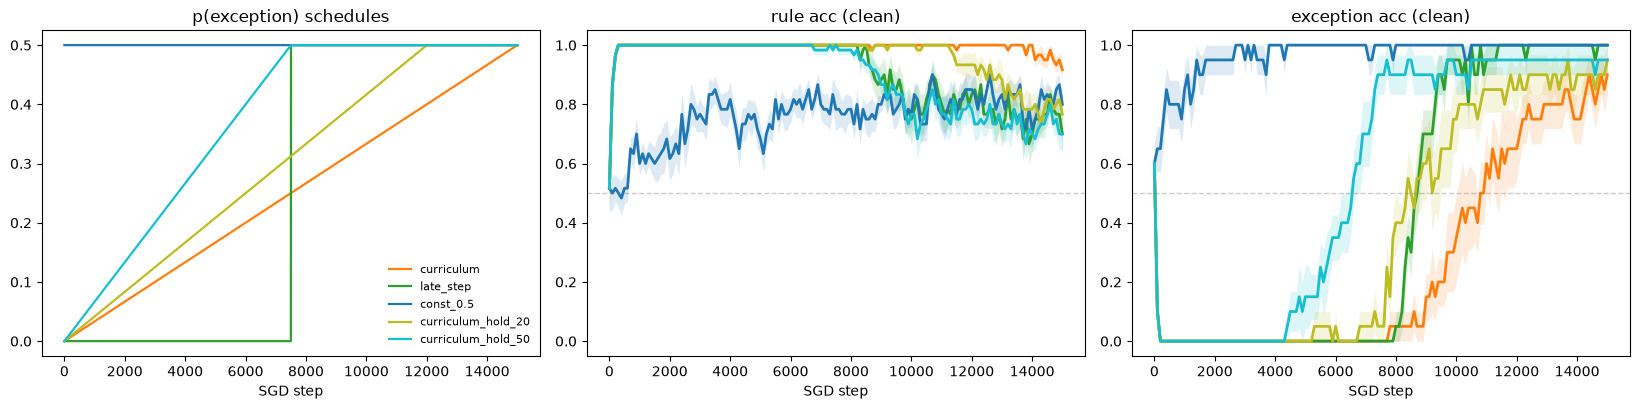

                   central_acc        peripheral_acc       
                          mean    sem           mean    sem
condition                                                  
curriculum               0.917  0.028           0.90  0.067
late_step                0.700  0.054           1.00  0.000
const_0.5                0.800  0.033           1.00  0.000
curriculum_hold_20       0.767  0.044           0.95  0.050
curriculum_hold_50       0.700  0.054           0.95  0.050

rule acc during the hold (mean over seeds):
  curriculum_hold_20: step 12000: 0.933   step 13500: 0.833   step 15000: 0.767
  curriculum_hold_50: step 7500: 1.000   step 9000: 0.867   step 10500: 0.783   step 15000: 0.700


In [17]:
# ── Ramp then HOLD at p = 0.5: is curriculum's rule advantage durable or transient? ──
def ramp_hold_schedule(T, ramp_frac):
    n_ramp = int(round(ramp_frac * T))
    p = np.full(T, 0.5, dtype=np.float32)
    p[:n_ramp] = np.linspace(0.0, 0.5, n_ramp)
    return p

HOLD_SCHEDS = {
    "curriculum_hold_20": ramp_hold_schedule(T_H, 0.8),   # 12000 ramp + 3000 hold @ 0.5
    "curriculum_hold_50": ramp_hold_schedule(T_H, 0.5),   # 7500 ramp + 7500 hold @ 0.5
}
print("mean p:", {k: round(float(v.mean()), 4) for k, v in HOLD_SCHEDS.items()},
      " (not exposure-matched — the question here is rule erosion at the endpoint)")

hist_R_list = []
for cond, sched in HOLD_SCHEDS.items():
    for sid in range(N_SEEDS_H):
        _, hist = train_one_run_probed(
            task_H, sched, seed=123 + sid, seed_id=sid, condition=cond,
            n_hidden=K_H, init_std=0.05, lr=0.01, eval_every=100)
        hist_R_list.append(hist)
    print(cond, "done")
hist_R = pd.concat(hist_R_list, ignore_index=True)
both_R = pd.concat([hist_H, hist_R], ignore_index=True)

HOLD_COLORS = {**COND_COLORS, "curriculum_hold_20": "C8", "curriculum_hold_50": "C9"}
show_R = ["curriculum", "late_step", "const_0.5",
          "curriculum_hold_20", "curriculum_hold_50"]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2))
ax = axes[0]
for cond in show_R:
    sched = HOLD_SCHEDS.get(cond, SCHEDULES_H.get(cond))
    ax.plot(sched, color=HOLD_COLORS[cond], lw=1.6, label=cond)
ax.set_title("p(exception) schedules")
ax.set_xlabel("SGD step")
ax.legend(frameon=False, fontsize=8)

for ax, metric, title in [(axes[1], "central_acc", "rule acc (clean)"),
                          (axes[2], "peripheral_acc", "exception acc (clean)")]:
    for cond in show_R:
        d = both_R[both_R["condition"] == cond]
        g = d.groupby("step")[metric]
        m, s = g.mean(), g.sem()
        ax.plot(m.index, m.values, color=HOLD_COLORS[cond], lw=2, label=cond)
        ax.fill_between(m.index, m - s, m + s, color=HOLD_COLORS[cond], alpha=0.15, lw=0)
    ax.set_title(title)
    ax.set_xlabel("SGD step")
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, color="gray", ls="--", lw=1, alpha=0.4)
plt.tight_layout()
plt.show()

fin_R = both_R[(both_R["step"] == T_H) & (both_R["condition"].isin(show_R))]
print(fin_R.groupby("condition")[["central_acc", "peripheral_acc"]]
      .agg(["mean", "sem"]).round(3).loc[show_R].to_string())
print("\nrule acc during the hold (mean over seeds):")
for cond, t0 in [("curriculum_hold_20", 12000), ("curriculum_hold_50", 7500)]:
    d = both_R[both_R["condition"] == cond].groupby("step")["central_acc"].mean()
    marks = sorted(set(m for m in [t0, t0 + 1500, t0 + 3000, T_H] if m <= T_H))
    print(f"  {cond}: " + "   ".join(f"step {m}: {d.loc[m]:.3f}" for m in marks))

**Result: delayed erosion, not protection — curriculum's rule advantage is a timed transient.**

- `curriculum_hold_20` sits at central 0.933 the moment its ramp reaches p = 0.5 (matching curriculum's final 0.917), then decays to 0.767 within the 3000-step hold — `const_0.5`'s level. `curriculum_hold_50` decays to 0.700 over its 7500-step hold — exactly `late_step`'s level after the same 7500 steps at p = 0.5. Time spent at high p is what erodes the rule, however gradually you arrived.
- This corrects the earlier reading that *abrupt* mixture shifts damage the rule: gradual arrival erodes identically once you stay. What the ramp actually buys is **less cumulative time at high p before evaluation**.
- Together with the settle control, the picture is fully symmetric — no hysteresis in either direction. Each mixture has one history-independent stationary state (p = 0.25: central 1.0 / peripheral ≈ 0.5; p = 0.5: central ≈ 0.7–0.8 / peripheral 1.0), with relaxation over a few thousand steps. Curriculum's endpoint (0.917 / 0.90) is **not the stationary state of any fixed mixture** — it exists only in transit.

**Why curriculum helps, final form:** at σ = 2, K = 32 no fixed exception rate is good at both item types — p = 0.25 loses the exceptions, p = 0.5 degrades the rule. But the two processes have different timescales: exceptions *install* fast (~1–3k steps at high p), the rule *erodes* slowly (~3k+ steps at p = 0.5). A ramp that reaches p = 0.5 exactly at evaluation harvests the fast gain before paying the slow cost. "Gradualness" matters only as the scheduling that makes arrival coincide with the end of training. Practical corollary: the benefit is horizon-dependent — train longer at the top and curriculum converges to `const_0.5`; evaluate mid-ramp and the tradeoff shifts again. Whether a regime exists where curriculum reaches a genuinely better *attractor* (below the Bayes flip, larger K, smaller lr) is the open question.